# M16 · Applications affines, graphes et variance d'un produit — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m16_couches_affines/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M16.1 à M16.6, M16.10 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M16.12 | La matrice homogène d'une application affine · `homogeneous_matrix` | 🔨 | ★ | 15 |
|  | M16.13 | Sommer sur les chemins d'un graphe sans cycle par les puissances de sa matrice · `sum_over_paths` | 🔨 | ★★ | 20 |
|  | M16.14 | Espérance et variance d'un produit de variables indépendantes · `variance_of_product` | 🔨 | ★ | 15 |
| B | M16.15 | Prédire l'écart-type d'une somme de produits aléatoires, mesures corrélées ou non, puis simuler | 🔮 | ★ | 10 |
|  | M16.16 | Une variance multipliée d'étage en étage : simuler une chaîne d'amplificateurs bruités | 🔬 | ★★ | 20 |
|  | M16.17 | L'image d'une figure par une suite d'applications affines du plan, en coordonnées homogènes | 🎨 | ★ | 15 |
| C | M16.18 | Chasse à l'erreur : une matrice homogène écrite pour des colonnes et appliquée à des lignes, Var(XY) = Var X · Var Y, et (I − A)⁻¹ sur un graphe qui a un cycle | 🐛 | ★ | 15 |
|  | M16.19 | Un test de propriété : la matrice homogène d'une composée est le produit des matrices homogènes | 🛠️ | ★ | 15 |
|  | M16.20 | Défi : la loi du produit de deux uniformes indépendantes, sa densité et ses deux premiers moments | 🏆 | ★★★ | 25 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : une application affine dans les deux conventions et ses paramètres, des matrices homogènes, leur produit et leur inverse, des chemins comptés par les puissances de la matrice d'adjacence, un planning de tâches sans cycle, la variance d'un produit et d'une somme de produits par des signes aléatoires, des points rangés en lignes et leurs images $\mathbf{X}\mathbf{W} + \mathbf{1}\mathbf{b}^\top$.
- Écrire les trois fonctions de `mymath/affine.py` et les tester.
- Prédire puis simuler l'écart-type d'une somme de produits, suivre une variance d'étage en étage, tracer les images d'une figure, corriger des erreurs classiques, écrire un test de propriété, et relever un défi : la loi du produit de deux uniformes.

**Rappel express.** En lignes, $\mathbf{x} \mapsto \mathbf{x}\mathbf{W} + \mathbf{b}$, $\mathbf{W}$ de forme $(n, m)$, $\mathbf{b}$ de forme $(m,)$, $nm + m$ paramètres ; en colonnes, la matrice est $\mathbf{W}^\top$. $[\mathbf{x}, 1]\,\mathbf{H} = [\mathbf{x}\mathbf{W} + \mathbf{b}, 1]$ avec $\mathbf{H} = \begin{pmatrix} \mathbf{W} & \mathbf{0} \\ \mathbf{b} & 1 \end{pmatrix}$ ; $f_1$ puis $f_2$ : $\mathbf{H}_1\mathbf{H}_2$. $(\mathbf{A}^k)_{ij}$ compte les chemins de $k$ arêtes de $i$ à $j$ ; sans cycle $\iff \mathbf{A}^n = \mathbf{0}$, et $(\mathbf{I} - \mathbf{A})^{-1} = \mathbf{I} + \mathbf{A} + \cdots + \mathbf{A}^{n-1}$. $X$, $Y$ indépendantes : $\mathbb{V}(XY) = \mathbb{V}(X)\,\mathbb{V}(Y) + \mathbb{V}(X)\,\mathbb{E}[Y]^2 + \mathbb{V}(Y)\,\mathbb{E}[X]^2$ ; des $\varepsilon_i$ centrés et indépendants de tout : $\mathbb{V}\big(\sum_i\varepsilon_ix_i\big) = \sum_i\mathbb{V}(\varepsilon_i)\,\mathbb{E}[x_i^2]$ ; $v_{k+1} = g^2v_k + s^2$.

## Partie 0 · Vérifier tes exercices papier (✏️ M16.1 à M16.6, 🔗 M16.10)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question ;
- une liste `[0.2, -1]` ;
- une matrice comme la liste de ses **lignes** : `[[1, 0], [-2, 3]]` ; un nombre décimal s'y écrit avec un point, `[[0.5, 1], [0, 2]]`, ou comme un calcul, `[[1/2, 1], [0, 2]]`.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly (SymPy) from the statements
import sympy

R = sympy.Rational


def rows(M):
    """A SymPy matrix as the list of its rows (Python ints, floats for the other numbers)."""
    return [[int(v) if v.is_Integer else float(v) for v in M.row(i)] for i in range(M.rows)]


def flat(M):
    """A SymPy row (or column) as a flat list (Python ints, floats for the other numbers)."""
    return [int(v) if v.is_Integer else float(v) for v in M]


def adjacency(n, edges):
    """The adjacency matrix of a directed graph with nodes 1 to n."""
    A = sympy.zeros(n, n)
    for i, j in edges:
        A[i - 1, j - 1] = 1
    return A


def out_degrees(A):
    return [int(sum(A.row(i))) for i in range(A.rows)]


def in_degrees(A):
    return [int(sum(A.col(j))) for j in range(A.cols)]


W_1, B_1 = sympy.Matrix([[1, 4], [0, 1], [-2, -1]]), sympy.Matrix([[3, -2]])              # M16.1: g(x) = x W + b
X_1C = sympy.Matrix([[2, -1, 1]])
X_1 = sympy.Matrix([[1, 0, 0], [0, 1, 0], [1, 1, 1]])
H1_2 = sympy.Matrix([[0, 1, 0], [-1, 0, 0], [0, 0, 1]])                                  # M16.2: points in rows
H2_2 = sympy.diag(2, 2, 1)
H3_2 = sympy.Matrix([[1, 0, 0], [0, 1, 0], [1, -3, 1]])
H_2, P_2 = H1_2 * H2_2 * H3_2, sympy.Matrix([[2, 1, 1]])
INV_2 = H_2.inv()
INV_KEPT_2 = INV_2.copy()                     # the translation of f undone without the linear part: −t
INV_KEPT_2[2, :2] = -H_2[2, :2]
INV_SIGN_2 = INV_2.copy()                     # the translation of f⁻¹ with the wrong sign
INV_SIGN_2[2, :2] = -INV_2[2, :2]
A_3 = adjacency(5, [(1, 2), (2, 3), (3, 1), (2, 4), (3, 4), (4, 5), (3, 5)])              # M16.3
TASKS_4 = ["Montage", "Commande", "Expédition", "Peinture", "Découpe", "Contrôle"]         # M16.4: numbers 1 to 6
EDGES_4 = [(TASKS_4.index(u) + 1, TASKS_4.index(v) + 1) for u, v in [
    ("Commande", "Découpe"), ("Commande", "Peinture"), ("Découpe", "Peinture"), ("Découpe", "Montage"),
    ("Peinture", "Montage"), ("Montage", "Contrôle"), ("Montage", "Expédition"), ("Contrôle", "Expédition")]]
A_4 = adjacency(6, EDGES_4)
PATHS_4 = sum((A_4 ** k for k in range(1, 6)), sympy.zeros(6, 6))     # A + A² + … + A⁵: the paths of every length
ORDER_4 = (2, 5, 4, 1, 6, 3)                   # Commande, Découpe, Peinture, Montage, Contrôle, Expédition
PERM_4 = sympy.Matrix(6, 6, lambda i, j: int(ORDER_4[i] - 1 == j))     # row i picks the old task ORDER_4[i]
RENUMBERED_4 = PERM_4 * A_4 * PERM_4.T
assert all(RENUMBERED_4[i, j] == 0 for i in range(6) for j in range(i + 1))   # strictly upper triangular
assert A_4 ** 5 != sympy.zeros(6, 6)           # a path through the six tasks: no other numbering works


def task(name):
    """The index (from 0) of a task in A_4."""
    return TASKS_4.index(name)


def one_length_4(source, target):
    """The wrong counts of paths of a single length (A, A², … or A⁵ alone) from source to target."""
    right = PATHS_4[task(source), task(target)]
    return {int((A_4 ** k)[task(source), task(target)]) for k in range(1, 6)} - {int(right)}


E_P5, V_P5, E_Q5, V_Q5 = 3, R(16, 100), 120, 400                                          # M16.5
M2_P5, M2_Q5 = V_P5 + E_P5 ** 2, V_Q5 + E_Q5 ** 2           # the second moments E[P²] and E[Q²]
V_R5 = M2_P5 * M2_Q5 - (E_P5 * E_Q5) ** 2
C_6 = sympy.Matrix([[4, 5, 1], [5, 9, 2], [1, 2, 1]])                                      # M16.6
AMPLITUDES_6 = [1, R(1, 2), 2]                              # ε_i = ± a_i
V_EPS_6 = [a ** 2 for a in AMPLITUDES_6]                    # V(ε_i) = a_i²
V_S_6 = sum(v * C_6[i, i] for i, v in enumerate(V_EPS_6))  # Σ V(ε_i) E[x_i²], centred measures
# d): Cov(ε₁x₁, ε₁x₂) = E[ε₁²] E[x₁x₂], one sign for both measures; g): V(x₁ + x₂ + x₃) + V(S), decorrelated (admitted)
W_10, B_10 = sympy.Matrix([[2, -1, 0], [1, 3, 1]]), sympy.Matrix([[1, 0, -2]])            # M16.10
X_10 = sympy.Matrix([[1, 1], [0, 2], [-1, 1], [2, 0]])
ONES_B_10 = sympy.ones(4, 1) * B_10                         # 1bᵀ: every row is b
H_10 = W_10.col_join(B_10).row_join(sympy.Matrix([0, 0, 1]))

**Ex M16.1 — Une application affine de ℝ³ dans ℝ² dans les deux conventions : formes, transposée, nombre de paramètres**

In [3]:
wbm.record("M16.1a", rows(W_1), mistakes={"en lignes, W a une ligne par ENTRÉE et une colonne par sortie : forme (3, 2)": rows(W_1.T)})
wbm.record("M16.1b", flat(B_1))
wbm.record("M16.1c", flat(X_1C * W_1 + B_1), mistakes={"g(x) = x W + b : n'oublie pas b": flat(X_1C * W_1)})
wbm.record("M16.1d", rows(W_1.T), mistakes={"en colonnes, c'est la transposée : une ligne par SORTIE, une colonne par entrée": rows(W_1)})
wbm.record("M16.1e", W_1.rows * W_1.cols + W_1.cols, mistakes={"b compte aussi : une coordonnée par sortie": W_1.rows * W_1.cols,
                     "un paramètre par coefficient de W et par coordonnée de b, pas un par entrée et par sortie":
                         W_1.rows + W_1.cols})
wbm.record("M16.1f", rows(X_1 * W_1 + sympy.ones(3, 1) * B_1), mistakes={"chaque image est x W + b : ajoute b à chaque ligne (le terme 1bᵀ)": rows(X_1 * W_1)})
wbm.record("M16.1g", 60 * 7 + 7, mistakes={"b compte aussi : une coordonnée par sortie": 60 * 7,
                     "W a un coefficient par couple (entrée, sortie) : n m coefficients, pas n + m": 60 + 7})
wbm.record("M16.1h", 500 * 60 * 7, mistakes={"chaque point a m sorties, et chacune demande n multiplications": 500 * 60,
                     "chaque sortie d'un point demande n multiplications, une par entrée": 500 * 7})

WBM_ANSWER {"decimals": 0, "element_hashes": ["1a7c32e81812eb10636ef1790cc828902505a59dd4096de444be27694109871d", "02b404eb554da6de8d7be1175740881f95d353f9774f6be3d5eba1dbcc2c7743", "d9387c7fffac7d57448c6bf498750228696e42f3dff84b6c9bbfb16a507b3285", "f2f43bc05d905d97229b5d15d2b767ef17f860ae20854bedd78dc30b80b03755", "22fbd887a0c57438f7b940ff51d7f273d796e189e9c4f3167503dc79ebe91400", "5dc76a335ff944ebaf55a6e7273170d701d6ba8099af693e172a23505f7105b8"], "hash": "074022dc1de603d27903f31a50de2aeaf8acc031bc7e0b30f7b03df282307cc9", "id": "M16.1a", "integer": true, "kind": "array", "mistakes": {"a3e3d3290504009f77ca0b03cd44e9fec17d5534890b5cbeaeacf60393eb2b81": "en lignes, W a une ligne par ENTRÉE et une colonne par sortie : forme (3, 2)"}, "shape": [3, 2]}
📝 Ex M16.1a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["4fc2a9e0bf26e2e14a1dcc883251d260b13bc91b01bf7fce0d6e41b0ba456d01", "ef76588cad157400a1efbdf8bcb553b5f653547114bd8030b27bee99a86d6261"], "h

**Ex M16.2 — Rotation, homothétie puis translation du plan : la matrice homogène de la composée, et celle de la réciproque**

In [4]:
wbm.record("M16.2a", rows(H1_2), mistakes={"avec des lignes, la ligne 1 de W est l'image de (1, 0), la ligne 2 celle de (0, 1)": rows(H1_2.T)})
wbm.record("M16.2b", rows(H2_2), mistakes={"la dernière case reste 1 : seule la partie linéaire est multipliée par 2": rows(2 * sympy.eye(3))})
wbm.record("M16.2c", rows(H3_2), mistakes={"avec des lignes, la translation va sur la dernière LIGNE, et la dernière colonne reste (0, 0, 1)":
                         rows(H3_2.T)})
wbm.record("M16.2d", rows(H_2), mistakes={"avec des lignes, la première application appliquée est à gauche du produit": rows(H3_2 * H2_2 * H1_2),
                     "vérifie H₁ sur le point (1, 0), qui doit aller en (0, 1) : avec des lignes, la ligne 1 de W est son image": rows(H1_2.T * H2_2 * H3_2)})
wbm.record("M16.2e", flat((P_2 * H_2)[:, :2]), mistakes={"avec des lignes, la première application appliquée est à gauche du produit : f₁ d'abord": flat((P_2 * H3_2 * H2_2 * H1_2)[:, :2]),
                     "l'image est un point du plan : deux coordonnées, sans le 1 final": flat(P_2 * H_2)})
wbm.record("M16.2f", rows(INV_2), decimals=2, mistakes={"on retire d'abord la translation, puis on défait la partie linéaire : la translation de la réciproque est transformée": rows(INV_KEPT_2),
                     "défaire une translation, c'est retrancher son vecteur : attention au signe": rows(INV_SIGN_2)})
wbm.record("M16.2g", flat((P_2 * H3_2 * H2_2 * H1_2)[:, :2]), mistakes={"g) applique f₃ d'abord, puis f₂, puis f₁ : l'ordre inverse de e)": flat((P_2 * H_2)[:, :2])})

WBM_ANSWER {"decimals": 0, "element_hashes": ["b81f859de369ecef6a09c88e5bed06811cfb9c0d4ede7288608e7eadaf224d67", "837c38ee27623512b78ed9f789d386d42f78919a890e294b713f2fdbed3eee5c", "b1653494b736497aee8fa4bcc8bff98fa67ab17b22a4ae7ae3f4fc2ee0f0f01e", "20b61f226f5692084d50a650bcf33d96c48c1feefa17cb48b203b6dc4cf30b22", "182a012813b443d57853b45ae568b1a044d194b514df4cbed58cdcf4fb282ce6", "95a49e2cebe0e08e960e67f6a09d290e769e57bb7822b99164619c62996e9ce0", "9fc56a9793738052dfc81f8215aa1bde4b2da02f803815508cb852536a32888f", "5e0a1245172eb12219bf4a189639f419d1ad5f81a04e42b8532ff6c22aca8ed4", "fd7f1a79b1a1f33279309f731bd9371728fde0df6e2a4371c935186bffe51894"], "hash": "0f8245451402b84ab361f072a3ebe3155fef3b714e10b57d3a4d195eb22061d9", "id": "M16.2a", "integer": true, "kind": "array", "mistakes": {"34b579edcda49b782877c46114c0108a58750ecea76c4481f07404a80357e506": "avec des lignes, la ligne 1 de W est l'image de (1, 0), la ligne 2 celle de (0, 1)"}, "shape": [3, 3]}
📝 Ex M16.2a : réponse enregist

**Ex M16.3 — Des rues à sens unique : degrés, matrice d'adjacence, et chemins de longueur 2 et 3 par ses puissances**

In [5]:
wbm.record("M16.3a", rows(A_3), mistakes={"A[i][j] = 1 pour une arête i → j : la ligne i liste les successeurs de i": rows(A_3.T)})
wbm.record("M16.3b", out_degrees(A_3), mistakes={"le degré sortant compte les rues qui PARTENT du carrefour : la somme de sa LIGNE": in_degrees(A_3)})
wbm.record("M16.3c", in_degrees(A_3), mistakes={"le degré entrant compte les rues qui ARRIVENT au carrefour : la somme de sa COLONNE": out_degrees(A_3)})
wbm.record("M16.3d", rows(A_3 ** 2), mistakes={"A² est le produit matriciel A A, pas le carré de chaque case": rows(A_3.multiply_elementwise(A_3)),
                     "A² se lit comme A : la case (i, j) compte les chemins qui partent de i et arrivent en j":
                         rows((A_3 ** 2).T)})
wbm.record("M16.3e", int((A_3 ** 2)[0, 3]), mistakes={"un chemin de longueur 2 : lis la case (1, 4) de A², pas celle de A": int(A_3[0, 3])})
wbm.record("M16.3f", int((A_3 ** 3)[0, 4]), mistakes={"un chemin de longueur 3 : la case (1, 5) de A³, pas celle de A²": int((A_3 ** 2)[0, 4]),
                     "à chaque carrefour, suis TOUTES les rues qui en partent : liste les chemins un par un": 1})
wbm.record("M16.3g", int((A_3 ** 3).trace()), mistakes={"chaque cycle compte une fois par carrefour de départ : la trace de A³": 1,
                     "des chemins de 3 rues : la diagonale de A³, pas celle de A²": int((A_3 ** 2).trace())})
wbm.record("M16.3h", int(sum(A_3 ** 2)), mistakes={"h) compte les chemins de 2 rues : la somme des cases de A², pas de A": int(sum(A_3))})

WBM_ANSWER {"decimals": 0, "element_hashes": ["d1375825cad747efab94484ab5aa24b379acd5e7e8788618207f2767f3d093ad", "bd48f8ab30456e4597eaffa86e2808df83048a1079dcc399a46345a2cece193f", "06598b00264f470c6ce72bf4a434ee1fb4b2761471b617d8bd9031029e18dab8", "930a9429b53049c52ed571fecd469052b24e04bb0ab8ad942a18db1b24b7ab15", "6db38dd436a566a6407c80933b9147e1ac6cb2805769d78ca6028911d23100d7", "262b190a2735cc5bf1f116b0782fc61b6dfd3d38bacf7e247c51f26076570f6b", "758ae20fc713ba59bb03ca82cd87def79b807e0d2ea8532f5a7840782183c5c4", "e1fd3e8883f33d27b4120c15383717d463f8706d64087a81b2e8c88628da3975", "b644b6205cf5a64acff509cc3e2fb7962ba77e8da4ffb9c0f6505093599f40fb", "a4ed15c8177bd6d24562da919d5a80a860ce69706bc329ea4661ce3515335aef", "68610afb6bd0f4cc38109eaa786ba9829e3f9b0ca11ee9730dd1b13ede6ccfef", "267a371ea5502858da3de370872dc3b3856ae1cf4c08331d411b7c3b91a31ebe", "f1b72bd09c74b74f561b7801bd52273d75e9677b1f0f847784fe00e79e28d7dd", "257aefaa340f992ca2f2dad88f366df46fd306fb575c998fb11a25c1c5cb0035", "8

**Ex M16.4 — Un planning de tâches : l'absence de cycle par les puissances de A, une numérotation qui la rend triangulaire, et le nombre de chemins entre deux tâches**

In [6]:
wbm.record("M16.4a", rows(A_4), mistakes={"A[i][j] = 1 quand la tâche i doit être finie avant la tâche j : la ligne i liste les tâches qui attendent i": rows(A_4.T)})
wbm.record("M16.4b", in_degrees(A_4), mistakes={"le degré entrant compte les arêtes qui ARRIVENT à la tâche : la somme de sa COLONNE": out_degrees(A_4)})
wbm.record("M16.4c", int((A_4 ** 2)[task('Commande'), task('Montage')]), mistakes={"un chemin DE Commande À Montage : la ligne de Commande, la colonne de Montage": int((A_4 ** 2)[task('Montage'), task('Commande')])})
wbm.record("M16.4d", int(PATHS_4[task('Commande'), task('Expédition')]), mistakes={"les chemins de TOUTES les longueurs comptent : additionne les cases de A, A², …, A⁵ (une seule puissance ne compte qu'une longueur)": one_length_4('Commande', 'Expédition')})
wbm.record("M16.4e", list(ORDER_4), mistakes={"toutes les arêtes doivent aller vers un numéro PLUS GRAND : une tâche avant celles qui en dépendent": list(reversed(ORDER_4))})
wbm.record("M16.4f", int(PATHS_4[task('Découpe'), task('Expédition')]), mistakes={"les chemins de TOUTES les longueurs comptent : additionne les cases de A, A², …, A⁵ (une seule puissance ne compte qu'une longueur)": one_length_4('Découpe', 'Expédition')})
wbm.record("M16.4g", int(sum(PATHS_4)), mistakes={"g) compte les chemins de toutes les longueurs, de 1 à 5 arêtes, pas seulement les arêtes": int(sum(A_4)),
                     "un chemin a au moins une arête : la somme porte sur A + A² + ⋯ + A⁵, sans I":
                         int(sum((sympy.eye(6) - A_4).inv()))})

WBM_ANSWER {"decimals": 0, "element_hashes": ["3cc17ae0feb9b927e3cdf78aaed95ca98f6cded1270fa76a3270ebbb54b47ca7", "2ae47f14d1f8ad889fa79808e58aa6e8803eae5eeda21b88eba0de56bbbf6365", "f3ae7056d21abcdfcbbd22040a96cf4fe5239e9300bc706a792df15c591f4477", "7c1b6002ce71b3a377f914d95b363cf865828bf5090a389c63f5fdf5484b1228", "c774f29e5ec51240a24e94667c24252783a81942e1e6e18ea1b0a2a0b3008620", "0ca47ae998623b30bc6d3f6d1e33e02a28abaffaa75dbcfce8d4f8358c71e85b", "434f3930e596141897b482d61ce856c7685294010c24b74042c537674af2b769", "f1602a5324d808a78cbf987bbe5c3389a917a8f2ae6b0bb39c7a67bd4e97606f", "55cba64f56b3028c1d19afa3cdc64eff2ae92c9991dcbe771378e52fff8d688f", "7faa9b11d24a9f1859402d0be649f248efd21a9aff9b6ab905beb8e56368a466", "d4ea31645788650b1b86ede20f0f177f67615b9c9147e416f395edbfdbf2f7c1", "768371720a4972a37714968774b43b1650d26a6bbf41b715817e9c75b1b01977", "52343e839087516a063c5f04c54280e12cca29b2e4c1995be0d3b685384fdf56", "0bfce42a6759eb7065f692346b8910a2ceecdada317c418e9ecb69608c8b4e6d", "d

**Ex M16.5 — Un prix aléatoire fois une quantité indépendante : espérance et variance du produit**

In [7]:
wbm.record("M16.5a", float(E_P5 * E_Q5), decimals=6)
wbm.record("M16.5b", float(M2_P5), decimals=6, mistakes={"E[X²] = V(X) + E[X]² : la variance ET le carré de la moyenne": float(E_P5 ** 2)})
wbm.record("M16.5c", float(M2_Q5), decimals=6, mistakes={"E[X²] = V(X) + E[X]² : la variance ET le carré de la moyenne": float(E_Q5 ** 2)})
wbm.record("M16.5d", float(V_R5), decimals=6, mistakes={"V(PQ) n'est pas V(P) V(Q) : les moyennes non nulles comptent": float(V_P5 * V_Q5),
                     "trois termes : le produit des variances compte aussi": float(V_R5 - V_P5 * V_Q5),
                     "trois termes : V(P) E[Q]² ET V(Q) E[P]², en plus de V(P) V(Q)":
                         {float(V_P5 * V_Q5 + V_P5 * E_Q5 ** 2), float(V_P5 * V_Q5 + V_Q5 * E_P5 ** 2)}})
wbm.record("M16.5e", float(sympy.sqrt(V_R5)), decimals=2, mistakes={"l'écart-type est la racine de la variance complète de d), pas de V(P) V(Q)":
                         float(sympy.sqrt(V_P5 * V_Q5)),
                     "la racine de la variance complète, avec ses trois termes": float(sympy.sqrt(V_R5 - V_P5 * V_Q5)),
                     "l'écart-type est la RACINE de la variance": float(V_R5)})
wbm.record("M16.5f", float(V_P5 * V_Q5), decimals=6)
wbm.record("M16.5g", float(sympy.sqrt(V_R5) / (E_P5 * E_Q5)), decimals=4, mistakes={"c_R = σ_R / E[R] : l'écart-type, la racine de la variance": float(V_R5 / (E_P5 * E_Q5)),
                     "σ_R vient de la variance complète de d), pas de V(P) V(Q)":
                         float(sympy.sqrt(V_P5 * V_Q5) / (E_P5 * E_Q5))})
wbm.record("M16.5h", float(E_P5 ** 2 * V_Q5), decimals=6, mistakes={"V(cQ) = c² V(Q) : un facteur constant sort de la variance, au carré": float(V_Q5),
                     "un facteur constant sort de la variance au CARRÉ": float(E_P5 * V_Q5)})

WBM_ANSWER {"coarse_any": {"0": ["3f8f94dfe95bc618c9fb68dda2eb4c38337daaa9d19c3fd1d7ec4a3fc03fbc10"]}, "coarser": {"1": ["bfd181abb4e2240f522232e21aeffec7dc92d06815a860fd5a97dcfccb72396e"], "2": ["a06f7fae006edae98b82a4c31e1487728e64909ad3e7c2c205bd8a769edba0f1"], "3": ["1f3253e7a828a4e37468851eda42a6dd5e0eadc1d4bd9431ff9c263a28014868"], "4": ["0b596221b254cc924a818f57b83653e7bd0837f69087f90e32eeefeb9fcffa0e"]}, "decimals": 6, "hash": "e01c1b61354f6036ba3d0a8621269b01d5a44216e07e3838c7a727a09c192dfb", "hash_coarse": "12ec7ba20fd1f18c2654846c2d20ba8c12ae4cc18fc8c001e4bc2cf297a31e5b", "id": "M16.5a", "kind": "float", "magnitude": 2, "sign": 1}
📝 Ex M16.5a : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"coarse_any": {"0": ["a8a0d49c285de2adcb1558a3c7fa5695134769f7a57d5facc307970aa5c56a96"]}, "coarser": {"1": ["24d81c4836f77ea785f2b9d267b1d529b810634c791a9218488b6def6dec3055"], "2": ["98a0c4305c4aee09dbac1a981cc3670e286558d1040daf1558a0c5ad83d48ab5"], "3": ["90172ee91c242fd33d69c0

**Ex M16.6 — Des signes aléatoires d'amplitudes différentes sur des mesures corrélées : la variance d'une somme de produits**

In [8]:
wbm.record("M16.6a", float(sum(C_6)), decimals=6, mistakes={"x₁, x₂, x₃ sont corrélées : la variance de la somme compte aussi les covariances":
                         float(C_6.trace())})
wbm.record("M16.6b", float(V_EPS_6[1]), decimals=6, mistakes={"la variance d'un signe ±a vaut a², pas a": float(AMPLITUDES_6[1]),
                     "ε₂ est centré, mais il n'est pas constant : sa variance est E[ε₂²]": 0.0})
wbm.record("M16.6c", float(V_S_6), decimals=6, mistakes={"chaque terme est multiplié par V(εᵢ), qui dépend de l'amplitude du signe": float(C_6.trace()),
                     "des signes centrés et indépendants rendent les produits décorrélés : les covariances disparaissent":
                         float(sum(C_6)),
                     "la variance d'un signe ±a vaut a², le carré de l'amplitude":
                         float(sum(a * C_6[i, i] for i, a in enumerate(AMPLITUDES_6)))})
wbm.record("M16.6d", float(V_EPS_6[0] * C_6[0, 1]), decimals=6, mistakes={"un même signe ne décorrèle pas : ε₁² = 1, il reste Cov(x₁, x₂)": 0.0})
wbm.record("M16.6e", float(V_S_6 + V_EPS_6[0] * 1 ** 2), decimals=6, mistakes={"c'est E[x₁²] = V(x₁) + E[x₁]² qui compte, pas V(x₁)": float(V_S_6)})
wbm.record("M16.6f", float(sum(C_6)), decimals=6, mistakes={"un seul signe pour les trois : les produits restent corrélés": float(V_S_6)})
wbm.record("M16.6g", float(sum(C_6) + V_S_6), decimals=6, mistakes={"la somme vaut (x₁ + x₂ + x₃) + S, deux morceaux décorrélés (admis) : la variance de S s'ajoute à celle de x₁ + x₂ + x₃": float(sum(C_6)),
                     "la somme vaut (x₁ + x₂ + x₃) + S, deux morceaux décorrélés (admis) : la variance de x₁ + x₂ + x₃ s'ajoute à celle de S": float(V_S_6),
                     "dans (x₁ + x₂ + x₃) + S, la première somme garde les covariances des mesures":
                         float(C_6.trace() + V_S_6)})

WBM_ANSWER {"coarse_any": {"0": ["809fc180410ebb0e86603742cae930d1296bbe157a253640342984d4c032ee23"]}, "coarser": {"1": ["fc8dbb7d34f042a566be022337e226304b04ea39c00665f412632eb43883f838"], "2": ["1034c912d369ae6987e8156d26eb0c3529e28c5d449eb283aef59ed243709231"], "3": ["d8a5c464e11db78e37ed942c9a16d9e46cefa146d5bf17d15e422777a62303b9"], "4": ["9200b4720d2ccb54a10f9c23bd8ed5c231cfac12c874aa527b5f28167cc246e1"]}, "decimals": 6, "hash": "8cae741a3d9b895431811eb6aab9241cef4a2caa23c5c2f76e400eecb002e1e9", "hash_coarse": "f5f5ae594ba4e2ff912f5032c2fe28a099d2e4c2952422f2d22879543238bb9a", "id": "M16.6a", "kind": "float", "magnitude": 1, "mistakes": {"9d3c8d48725b9e2b58b1a6b8f6bd9c035059350fbcea471e5aab471107b2c0b8": "x₁, x₂, x₃ sont corrélées : la variance de la somme compte aussi les covariances"}, "sign": 1}
📝 Ex M16.6a : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"coarse_any": {"1": ["fdcdf7cb7a6fa7b85b55ae6539a78cc8a79597f7f6594be0f65ffb432082f404", "e6027720ddad2947537e5d1b2b

**Ex M16.10 — Pont : n points rangés en lignes, X W + 1bᵀ, et la diffusion de b**

In [9]:
wbm.record("M16.10a", list((X_10 * W_10).shape), mistakes={"le produit (N, n) × (n, m) a la forme (N, m) : une colonne par SORTIE": list(X_10.shape),
                     "une ligne par point : la forme est (nombre de points, nombre de sorties)":
                         list((X_10 * W_10).T.shape)})
wbm.record("M16.10b", rows(ONES_B_10), mistakes={"1bᵀ a une ligne par point, et chacune vaut b": rows(ONES_B_10.T)})
wbm.record("M16.10c", rows(X_10 * W_10 + ONES_B_10), mistakes={"ajoute b à chaque ligne : X W + 1bᵀ": rows(X_10 * W_10)})
wbm.record("M16.10d", rows(H_10), mistakes={"en lignes, W en haut à gauche et b sur la dernière LIGNE, suivi de 1": rows(H_10.T)})
wbm.record("M16.10e", rows(X_10.row_join(sympy.ones(4, 1)) * H_10), mistakes={"[X | 1] H garde la dernière coordonnée de chaque point": rows(X_10 * W_10 + ONES_B_10)})
wbm.record("M16.10f", X_10.rows * W_10.rows * W_10.cols, mistakes={"chaque sortie de chaque point demande n multiplications, une par entrée": X_10.rows * W_10.cols,
                     "f) compte le produit X W, pas [X | 1] H": X_10.rows * (W_10.rows + 1) * (W_10.cols + 1)})

WBM_ANSWER {"decimals": 0, "element_hashes": ["f98a67ed9943a9ac7180ddcfa56e67bf84bbdfa8fd89e2fb3032c3782ed07801", "12c1c3869b23555230d5c88826b08e0d28af7410b4f85e92fbcbcdc736bc2655"], "hash": "7c02504e64e387a3e5bf244af94c1798fc127922531e0060a0c4c6e9aae5909d", "id": "M16.10a", "integer": true, "kind": "array", "mistakes": {"67c6ddc25743e6de6e4ca3e778dbdb056d1f880a4418ed47467d00d4a39f3e47": "le produit (N, n) × (n, m) a la forme (N, m) : une colonne par SORTIE", "9a25cc1c88fe7798bc19206f219a0afd90e81b26a3d2babc7bb6e8f5f1a5199d": "une ligne par point : la forme est (nombre de points, nombre de sorties)"}, "shape": [2]}
📝 Ex M16.10a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["9d1751ebfd2ac666a64905dc1be6625598856a1b805d97513dd1789c15f528bc", "d30a2ae90dfb31ace94c3ac3923be4aa498153d65173a983e7a76717d9185e99", "806fece3337be45eb508748282f1b41d6ccee6ac328e49736212d5580e5ecb7d", "27eefee7ae54bc9565a0e5c13d247133fa18531997c6fc72f2218493924d4f5c", "75

## Partie A · Ta librairie : la matrice homogène, la somme sur les chemins et la variance d'un produit

Fiche §2 à §5. Les trois fonctions de `mymath/affine.py`, leurs tests, et un usage de chacune.

In [10]:
# Tools of the notebook (parts A to C)
import inspect
import math
import warnings

import matplotlib.pyplot as plt
import numpy as np

from wbm.nbtools import StopCheck, checked, drawn, fr, run_pytest_group, verdict

### Ex M16.12 — La matrice homogène d'une application affine · `homogeneous_matrix` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer la matrice homogène d'une application affine pour des points en lignes, et s'en servir pour calculer une image.  
**Prérequis :** fiche §2 · **mymath :** `affine.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M03). Ouvre ta copie `mon_travail/mymath/affine.py`, lis la docstring du module puis celle de la fonction, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. NumPy est permis (`@`, `np.zeros`, `np.eye`, `np.hstack`, `np.vstack`…), mais pas `np.linalg.matrix_power`, `np.linalg.inv` ni `np.linalg.solve` dans `sum_over_paths` (les tests comparent tes résultats aux leurs, et un test vérifie que tu ne t'en sers pas). Ne modifie jamais les tableaux reçus : travaille sur une copie, `np.array(x, dtype=float)`. Les nombres se rendent en `float` de Python, les matrices en tableaux NumPy de flottants.

Écris `homogeneous_matrix(W, b)` (fiche §2), en suivant sa docstring : `ValueError` si `W` n'est pas un tableau 2-D, si `b` n'est pas 1-D ou si `len(b) != W.shape[1]` ; sinon la matrice $(n + 1, m + 1)$
$$\mathbf{H} = \begin{pmatrix} \mathbf{W} & \mathbf{0} \\ \mathbf{b} & 1 \end{pmatrix},$$
avec $\mathbf{W}$ en haut à gauche, une colonne de $n$ zéros à droite, puis la ligne $\mathbf{b}$ suivie de 1 : elle envoie $[\mathbf{x}, 1]$ sur $[\mathbf{x}\mathbf{W} + \mathbf{b}, 1]$.

Les tests tournent d'abord. La cellule d'usage calcule ensuite, avec ta fonction, la matrice homogène de l'application $\mathbf{x} \mapsto \mathbf{x}\mathbf{W} + \mathbf{b}$ de la cellule fournie ($\mathbf{W} = \begin{pmatrix} 1 & -3 \\ 0 & 2 \end{pmatrix}$, $\mathbf{b} = (3, 1)$), puis $[2, -1, 1]\,\mathbf{H}$ :
- a) l'image du point $(2, -1)$, les deux premières coordonnées de $[2, -1, 1]\,\mathbf{H}$ (vérifiée par `wbm.check`).

Dans ta copie : écris $\mathbf{H}$ à la main et refais a). Pourquoi la dernière coordonnée de $[\mathbf{x}, 1]\,\mathbf{H}$ vaut-elle 1 pour tout $\mathbf{x}$ ? Quelle est la forme de la matrice homogène d'une application de $\mathbb{R}^4$ dans $\mathbb{R}^2$, et que vaut sa dernière colonne ?

In [11]:
W_12 = np.array([[1.0, -3.0],
                 [0.0, 2.0]])        # an affine map of the plane, x ↦ x W_12 + B_12 (points in rows)
B_12 = np.array([3.0, 1.0])
P_12 = np.array([2.0, -1.0])         # a point of the plane

In [12]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [13]:
run_pytest_group("tests/test_m16_affine.py", "test_homogeneous", impl="ref")

pytest: 14 réussi(s), 35 non sélectionné(s) en 0,04 s


**L'usage** : la matrice homogène de `W_12` et `B_12`, puis l'image de $(2, -1)$.

In [14]:
H_12 = mymath.affine.homogeneous_matrix(W_12, B_12)
image_12 = np.append(P_12, 1.0) @ H_12
print("H =", H_12.tolist())
print("[x, 1] H =", image_12.tolist(), " ; a)", image_12[:2].tolist())

H = [[1.0, -3.0, 0.0], [0.0, 2.0, 0.0], [3.0, 1.0, 1.0]]
[x, 1] H = [5.0, -7.0, 1.0]  ; a) [5.0, -7.0]


In [15]:
w_12r, b_12r, p_12r = np.array([[1.0, -3.0], [0.0, 2.0]]), np.array([3.0, 1.0]), np.array([2.0, -1.0])
wbm.record("M16.12a", (p_12r @ w_12r + b_12r).tolist(),
           mistakes={"la translation manque : b va sur la dernière LIGNE de H, que le 1 de [x, 1] multiplie":
                         (p_12r @ w_12r).tolist(),
                     "c'est la matrice pour des colonnes : avec des lignes, W en haut à gauche, b sur la dernière ligne, "
                     "et la dernière colonne (0, …, 0, 1)": (p_12r @ w_12r.T).tolist(),
                     "W est rangée dans la mauvaise convention : en lignes, x W, avec W de forme (n, m)":
                         (p_12r @ w_12r.T + b_12r).tolist()})

WBM_ANSWER {"decimals": 0, "element_hashes": ["a94750e86bdb523670765a7ba3ffd3af8f9c936512731c8c0f57d3bb2a8ba70d", "15cb90b61357c4a85c11b5494e660b4cabe2342f6ddfccdc3cb6c483f6df4267"], "hash": "82d57ea2b0a722a25d9000d7e28ee0e671884dec55b8df4c08af7f49382f7afa", "id": "M16.12a", "integer": true, "kind": "array", "mistakes": {"79890bb60d018184a0bc191095eedb482d2c80e7e505b6db8285e8b3dbca7b5a": "la translation manque : b va sur la dernière LIGNE de H, que le 1 de [x, 1] multiplie", "bdbeeb4c06b4269faf0f7f1e77f3b7ed8e50aa3fafc4600f1529ce3d4230e1c0": "c'est la matrice pour des colonnes : avec des lignes, W en haut à gauche, b sur la dernière ligne, et la dernière colonne (0, …, 0, 1)", "f19e701b2c42e24b8a6d028bc55619ca6fb24c6e15cc648710db73234007f102": "W est rangée dans la mauvaise convention : en lignes, x W, avec W de forme (n, m)"}, "shape": [2]}
📝 Ex M16.12a : réponse enregistrée (array, 0 décimale).


💡 $\mathbf{H} = \begin{pmatrix} 1 & -3 & 0 \\ 0 & 2 & 0 \\ 3 & 1 & 1 \end{pmatrix}$, et $[2, -1, 1]\,\mathbf{H} = (2 + 3,\ -6 - 2 + 1,\ 1) = (5, -7, 1)$ : a) $(5, -7)$. La dernière colonne de $\mathbf{H}$, $(0, 0, 1)$, lit la dernière coordonnée de $[\mathbf{x}, 1]$ : elle vaut toujours 1. Pour une application de $\mathbb{R}^4$ dans $\mathbb{R}^2$, $\mathbf{H}$ a la forme $(5, 3)$, de dernière colonne $(0, 0, 0, 0, 1)$. Les deux erreurs de rangement se voient sur un seul point : sans la ligne $\mathbf{b}$, l'image serait $(2, -8)$ ; avec la matrice pour des colonnes, $(5, -2)$, et une dernière coordonnée qui ne vaut plus 1.

### Ex M16.13 — Sommer sur les chemins d'un graphe sans cycle par les puissances de sa matrice · `sum_over_paths` 🔨 ★★ ⏱️ 20 min
**Objectif :** programmer la somme sur les chemins d'un graphe sans cycle par les puissances de sa matrice, après avoir vérifié l'absence de cycle, et compter les chemins d'un quartier en grille.  
**Prérequis :** fiche §3 et §4 · **mymath :** `affine.py` · **Parcours :** C, E

Écris `sum_over_paths(weights, source, target)` (fiche §3 et §4), en suivant sa docstring : `ValueError` si `weights` n'est pas une matrice carrée, si un nœud n'est pas un entier de $[0, n - 1]$, ou si le graphe a un cycle (le message est `"the graph has a cycle"`) ; sinon la somme, sur tous les chemins de `source` à `target`, des produits des poids de leurs arêtes, $\sum_{k \ge 1}(\mathbf{A}^k)_{st}$, un `float` ($0$ quand `source == target`). Le cycle se cherche sur le **motif** des poids non nuls, `weights != 0`, par ses puissances booléennes : le graphe est sans cycle si et seulement si la $n$-ième est nulle. Pas de `np.linalg.matrix_power`, de `np.linalg.inv` ni de `np.linalg.solve` : un produit `@` par puissance.

La cellule fournie construit `GRID_13`, la matrice d'adjacence d'un quartier de $5 \times 5$ carrefours : le carrefour $(i, j)$, pour $i$ et $j$ de 0 à 4, est le nœud $5i + j$, et des rues à sens unique vont vers l'est, $(i, j) \to (i + 1, j)$, et vers le nord, $(i, j) \to (i, j + 1)$. Avec ta fonction, calcule :
- a) le nombre de chemins du coin $(0, 0)$ au coin $(4, 4)$.

Une dernière cellule ajoute à la grille une rue en travers qui revient en arrière, de $(2, 2)$ vers $(1, 2)$ : ta fonction doit alors lever `ValueError`.

Dans ta copie : retrouve a) par un dénombrement (R8) : un chemin du coin $(0, 0)$ au coin $(4, 4)$ est une suite de pas vers l'est et vers le nord ; combien de pas de chaque sorte ? Pourquoi tous ces chemins ont-ils la même longueur, et quelle puissance de `GRID_13` les compte ? Avec la rue qui revient en arrière, pourquoi la « somme sur les chemins » n'a-t-elle plus de sens ? Combien de produits `@` ta fonction fait-elle pour 25 nœuds ?

In [16]:
SIZE_13 = 5                                    # a grid of 5 × 5 crossroads
GRID_13 = np.zeros((SIZE_13 ** 2, SIZE_13 ** 2))   # the crossroads (i, j) is the node 5 i + j
for i in range(SIZE_13):
    for j in range(SIZE_13):
        if i + 1 < SIZE_13:
            GRID_13[SIZE_13 * i + j, SIZE_13 * (i + 1) + j] = 1.0   # the one-way street to the east, (i, j) → (i + 1, j)
        if j + 1 < SIZE_13:
            GRID_13[SIZE_13 * i + j, SIZE_13 * i + j + 1] = 1.0     # the one-way street to the north, (i, j) → (i, j + 1)

In [17]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [18]:
run_pytest_group("tests/test_m16_affine.py", "test_paths or test_sum_over_paths", impl="ref")

pytest: 23 réussi(s), 26 non sélectionné(s) en 0,05 s


**L'usage** : les chemins du quartier en grille.

In [19]:
sum_over_paths = mymath.affine.sum_over_paths
answer_M16_13a = sum_over_paths(GRID_13, 0, SIZE_13 ** 2 - 1)           # from the node 0 = (0, 0) to the node 24 = (4, 4)
print("a)", answer_M16_13a, " ; dans l'autre sens :", sum_over_paths(GRID_13, SIZE_13 ** 2 - 1, 0))
power_13 = np.linalg.matrix_power(GRID_13, 8)                      # (here only, to check: every path has 8 streets)
print("chemins de 8 rues :", power_13[0, -1], " ; une puissance nulle à partir de k =",
      next(k for k in range(1, 26) if not np.linalg.matrix_power(GRID_13, k).any()))

a) 70.0  ; dans l'autre sens : 0.0
chemins de 8 rues : 70.0  ; une puissance nulle à partir de k = 9


In [20]:
wbm.record("M16.13a", math.comb(8, 4),
           mistakes={"aucun chemin ne va du coin (4, 4) au coin (0, 0) : sum_over_paths(weights, source, target) part de "
                     "source, et le carrefour (i, j) est le nœud 5i + j": 0})

WBM_ANSWER {"hash": "b318edcf2a59fb2f9d79548d156955a9c434ea584cd360175afdb4f3de3a6243", "id": "M16.13a", "kind": "int", "magnitude": 1, "mistakes": {"04af00c7fff78ba841609af6f2a01a95b86722f6e4be623bf09d22cc5decac75": "aucun chemin ne va du coin (4, 4) au coin (0, 0) : sum_over_paths(weights, source, target) part de source, et le carrefour (i, j) est le nœud 5i + j"}, "sign": 1}
📝 Ex M16.13a : réponse enregistrée (int).


In [21]:
with checked("M16.13"):                       # the same grid, and one street that goes back
    back_13 = GRID_13.copy()
    back_13[SIZE_13 * 2 + 2, SIZE_13 * 1 + 2] = 1.0    # the street (2, 2) → (1, 2), against the street (1, 2) → (2, 2)
    try:
        value_13 = mymath.affine.sum_over_paths(back_13, 0, SIZE_13 ** 2 - 1)
    except NotImplementedError:
        raise
    except ValueError as exc:
        print(f"✅ Ex M16.13 : avec la rue qui revient en arrière, sum_over_paths lève ValueError : {exc}")
    else:
        print(f"❌ Ex M16.13 : avec la rue qui revient en arrière, le graphe a un cycle, et sum_over_paths rend "
              f"{value_13!r} au lieu de lever ValueError(\"the graph has a cycle\")")

✅ Ex M16.13 : avec la rue qui revient en arrière, sum_over_paths lève ValueError : the graph has a cycle


💡 a) Un chemin de $(0, 0)$ à $(4, 4)$ fait 4 pas vers l'est et 4 vers le nord, dans un ordre quelconque : $\binom{8}{4} = 70$ chemins, tous de 8 rues, donc tous comptés par $(\mathbf{A}^8)_{0,24}$. Les rues vont toujours vers $i + j$ plus grand : le graphe est sans cycle, et $\mathbf{A}^9 = \mathbf{0}$ (le plus long chemin du quartier a 8 rues), bien avant $\mathbf{A}^{25}$. Dans l'autre sens, de $(4, 4)$ à $(0, 0)$, il n'y a aucun chemin : 0. Avec la rue $(2, 2) \to (1, 2)$, la boucle $(1, 2) \to (2, 2) \to (1, 2)$ se parcourt autant de fois qu'on veut : il y a une infinité de chemins de $(0, 0)$ à $(4, 4)$, et la somme n'a plus de sens. La référence fait $n - 1 = 24$ produits booléens pour le test de cycle, puis autant pour les puissances ; on pourrait s'arrêter dès qu'une puissance est nulle (ici dès $\mathbf{A}^9$).

### Ex M16.14 — Espérance et variance d'un produit de variables indépendantes · `variance_of_product` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer l'espérance et la variance d'un produit de variables indépendantes, et s'en servir pour l'incertitude d'une surface.  
**Prérequis :** fiche §5 · **mymath :** `affine.py` · **Parcours :** C

Écris `variance_of_product(mean_x, var_x, mean_y, var_y)` (fiche §5), en suivant sa docstring : `ValueError` si une variance est négative (ou si un argument n'est pas un nombre fini) ; sinon le couple $\big(\mathbb{E}[XY], \mathbb{V}(XY)\big)$ pour $X$ et $Y$ indépendantes, deux `float` :
$$\mathbb{E}[XY] = \mathbb{E}[X]\,\mathbb{E}[Y], \qquad \mathbb{V}(XY) = \mathbb{V}(X)\,\mathbb{V}(Y) + \mathbb{V}(X)\,\mathbb{E}[Y]^2 + \mathbb{V}(Y)\,\mathbb{E}[X]^2.$$

**L'usage.** Un champ rectangulaire est mesuré au décamètre : sa longueur $L$ a pour espérance 85 m et pour écart-type 0,4 m, sa largeur $\ell$ pour espérance 42 m et pour écart-type 0,3 m, les deux mesures étant indépendantes (cellule fournie). Avec ta fonction, calcule :
- a) l'écart-type de la surface $L\ell$, en m² (2 décimales).

Dans ta copie : lequel des trois termes de la variance domine, et pourquoi le produit des variances ne compte-t-il presque pas ? Retrouve a) par la forme multiplicative $1 + c_{L\ell}^2 = (1 + c_L^2)(1 + c_\ell^2)$. Que deviendrait a) si la longueur était connue exactement ?

In [22]:
MEAN_L_14, SD_L_14 = 85.0, 0.4      # the length of the field, in m: its expectation and its standard deviation
MEAN_W_14, SD_W_14 = 42.0, 0.3      # its width, in m (the two measures are independent)

In [23]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [24]:
run_pytest_group("tests/test_m16_affine.py", "test_product", impl="ref")

pytest: 12 réussi(s), 37 non sélectionné(s) en 0,04 s


**L'usage** : l'incertitude de la surface du champ.

In [25]:
variance_of_product = mymath.affine.variance_of_product
mean_14, var_14 = variance_of_product(MEAN_L_14, SD_L_14 ** 2, MEAN_W_14, SD_W_14 ** 2)   # variances, not deviations
answer_M16_14a = round(math.sqrt(var_14), 2)
print("E[L ℓ] =", mean_14, "m² ; V(L ℓ) =", round(var_14, 4), " ; a)", answer_M16_14a, "m²")
print("les trois termes :", round(SD_L_14 ** 2 * SD_W_14 ** 2, 4), round(SD_L_14 ** 2 * MEAN_W_14 ** 2, 4),
      round(SD_W_14 ** 2 * MEAN_L_14 ** 2, 4))
print("par la forme multiplicative :",
      round(mean_14 * math.sqrt((1 + (SD_L_14 / MEAN_L_14) ** 2) * (1 + (SD_W_14 / MEAN_W_14) ** 2) - 1), 4),
      " ; longueur exacte :", round(SD_W_14 * MEAN_L_14, 2))

E[L ℓ] = 3570.0 m² ; V(L ℓ) = 932.5044  ; a) 30.54 m²
les trois termes : 0.0144 282.24 650.25
par la forme multiplicative : 30.5369  ; longueur exacte : 25.5


In [26]:
sl_14r, sw_14r = 0.4, 0.3
wbm.record("M16.14a", math.sqrt(sl_14r ** 2 * sw_14r ** 2 + sl_14r ** 2 * 42 ** 2 + sw_14r ** 2 * 85 ** 2), decimals=2,
           mistakes={"V(L ℓ) n'est pas V(L) V(ℓ) : les moyennes non nulles comptent": sl_14r * sw_14r,
                     "variance_of_product prend des VARIANCES : le carré de chaque écart-type":
                         math.sqrt(sl_14r * sw_14r + sl_14r * 42 ** 2 + sw_14r * 85 ** 2),
                     "a) demande l'écart-type, la racine de la variance":
                         sl_14r ** 2 * sw_14r ** 2 + sl_14r ** 2 * 42 ** 2 + sw_14r ** 2 * 85 ** 2})

WBM_ANSWER {"coarse_any": {"0": ["322feed35f3814879f19e9836b844b8b11af72f94a6b152c0d127231d250cf3f"]}, "decimals": 2, "hash": "5a32f30b959a41611eb5060fa15221212203efea29b73ddc20c89854c7e3ab41", "hash_coarse": "4fa71dcda0943cbfc1e6adcb3dd30e05c5117f7021acf4e86532800078e88e2b", "id": "M16.14a", "kind": "float", "magnitude": 1, "mistakes": {"0d1f660f8ff32adc1db5a8f7d17f8440217e15ab0ee3bedfe2d3a3b89e6a0c42": "a) demande l'écart-type, la racine de la variance", "24e8569ff8e8e2fca0ae458aa0f22340e875875c9999cc25055a2ec0cded4583": "V(L ℓ) n'est pas V(L) V(ℓ) : les moyennes non nulles comptent", "917004db69d3f30f11c808e3b0d3d9a4a7355241929dcda3a2baa62c056e8fe2": "variance_of_product prend des VARIANCES : le carré de chaque écart-type"}, "sign": 1}
📝 Ex M16.14a : réponse enregistrée (float, 2 décimales).


💡 $\mathbb{E}[L\ell] = 85 \times 42 = 3\,570$ m², et $\mathbb{V}(L\ell) = 0{,}16 \times 0{,}09 + 0{,}16 \times 42^2 + 0{,}09 \times 85^2 = 0{,}0144 + 282{,}24 + 650{,}25 = 932{,}5044$ : a) $\approx 30{,}54$ m². Le terme $\mathbb{V}(\ell)\,\mathbb{E}[L]^2$ domine : une erreur de 0,3 m sur la largeur est multipliée par une longueur de 85 m. Le produit des variances, $0{,}0144$, ne change même pas la deuxième décimale de l'écart-type. Par la forme multiplicative, $c_L \approx 0{,}0047$ et $c_\ell \approx 0{,}0071$ : $3\,570\sqrt{(1 + c_L^2)(1 + c_\ell^2) - 1} \approx 30{,}54$. Si la longueur était exacte, l'écart-type serait $85 \times 0{,}3 = 25{,}5$ m².

## Partie B · Des expériences et une figure

Fiche §2, §6 et §7. L'écart-type d'une somme de produits par des signes aléatoires, prédit puis simulé ; une variance multipliée d'étage en étage ; les images d'une figure par des applications affines.

### Ex M16.15 — Prédire l'écart-type d'une somme de produits aléatoires, mesures corrélées ou non, puis simuler 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir l'écart-type d'une somme de mesures, corrélées ou non, avec ou sans signes aléatoires, puis le vérifier par une simulation.  
**Prérequis :** fiche §6 et §7 · **Parcours :** C, E

On additionne $n = 25$ mesures $x_1, \ldots, x_{25}$, chacune de loi $\mathcal{N}(0, 1)$, dans deux cas. **Cas 1** : les 25 mesures sont **égales**, $x_i = x$ pour tout $i$, avec $x$ de loi $\mathcal{N}(0, 1)$ (un seul tirage, recopié 25 fois). **Cas 2** : les 25 mesures sont **indépendantes**. On les multiplie aussi par des multiplicateurs aléatoires : $\varepsilon_1, \ldots, \varepsilon_{24}$ valent $\pm 1$ et $\varepsilon_{25}$ vaut $\pm 5$, chacun prenant ses deux valeurs avec la probabilité $\frac{1}{2}$, indépendamment des autres et des mesures. Pour chaque question, choisis le numéro de la bonne réponse :
- a) l'écart-type de $\sum_i x_i$ dans le cas 1 : (1) 5 ; (2) 25 ; (3) 625 ;
- b) l'écart-type de $\sum_i x_i$ dans le cas 2 : (1) 5 ; (2) 25 ; (3) 1 ;
- c) l'écart-type de $\sum_i \varepsilon_ix_i$ dans le cas 1 : (1) 5 ; (2) 7 ; (3) 29 ;
- d) l'écart-type de $\sum_i \varepsilon_ix_i$ dans le cas 2 : (1) 5 ; (2) 7 ; (3) 49.

**Avant d'exécuter quoi que ce soit**, écris tes quatre prédictions (le **numéro du choix**), vérifie-les, puis lance l'expérience : 200 000 tirages de chaque cas (graine 4931).

In [27]:
N_15, N_DRAWS_15 = 25, 200000        # 25 measures, 200 000 draws

In [28]:
wbm.record("M16.15a", 2, prediction=True, choices=[1, 2, 3])
wbm.record("M16.15b", 1, prediction=True, choices=[1, 2, 3])
wbm.record("M16.15c", 2, prediction=True, choices=[1, 2, 3])
wbm.record("M16.15d", 2, prediction=True, choices=[1, 2, 3])

WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "295953e37721623fe946c22e2e9068108dca8f876d97e1fd926fa350d07baf39", "id": "M16.15a", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M16.15a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "b096f9ce0f426f9a3ddfc149a389f8315433aefe284faf744183ba1972c0c3f0", "id": "M16.15b", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M16.15b : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "1942f6aa29a19169152285c6bd687089e2006ee68c588c69a59fb9cd8fd50690", "id": "M16.15c", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M16.15c : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "923232b5b120f636a964835638473b96cf30aca4da5742f1110815b948dc645d", "id": "M16.15d", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M16.15d : réponse enregistrée (int).


**L'expérience.** Elle ne s'exécute qu'une fois tes quatre prédictions écrites.

In [29]:
rng_15 = np.random.default_rng(4931)
same_15 = np.repeat(rng_15.normal(size=(N_DRAWS_15, 1)), N_15, axis=1)   # case 1: the 25 measures are equal
independent_15 = rng_15.normal(size=(N_DRAWS_15, N_15))                  # case 2: 25 independent measures
signs_15 = rng_15.choice([-1.0, 1.0], size=(N_DRAWS_15, N_15))           # independent random signs ±1
signs_15[:, -1] *= 5                                                     # the last multiplier is ±5
for case_15, measures_15 in (("cas 1, mesures égales", same_15), ("cas 2, mesures indépendantes", independent_15)):
    plain_15 = float(np.std(measures_15.sum(axis=1)))
    signed_15 = float(np.std((signs_15 * measures_15).sum(axis=1)))
    print(f"{case_15} : écart-type de Σ xᵢ ≈ {plain_15:.3f} ; de Σ εᵢxᵢ ≈ {signed_15:.3f}".replace(".", ","))

cas 1, mesures égales : écart-type de Σ xᵢ ≈ 25,003 ; de Σ εᵢxᵢ ≈ 7,005


cas 2, mesures indépendantes : écart-type de Σ xᵢ ≈ 4,996 ; de Σ εᵢxᵢ ≈ 7,009


**Après l'expérience**, dans ta copie : écris la variance de chaque somme, et dis ce qui s'additionne (les variances, les écarts-types, les covariances). Que prédit le lemme du §6 (admis) pour c) et d), et pourquoi c) et d) sont-elles égales, alors que a) et b) diffèrent tant ? Que deviendrait c) avec **un seul** signe $\varepsilon = \pm 1$ pour les 25 mesures ? Pour $n$ mesures indépendantes, comment l'écart-type de la somme et celui de la moyenne varient-ils avec $n$ ?

💡 a) Dans le cas 1, $\sum_i x_i = 25x$ : variance $25^2 = 625$, écart-type 25 (choix 2) ; les 625 covariances, toutes égales à 1, s'additionnent. b) Dans le cas 2, les covariances sont nulles : variance 25, écart-type 5 (choix 1). c) et d) Le lemme du §6 (admis) s'applique dans les deux cas : $\mathbb{V}\big(\sum_i\varepsilon_ix_i\big) = \sum_i\mathbb{V}(\varepsilon_i)\,\mathbb{E}[x_i^2] = 24 \times 1 + 25 \times 1 = 49$, écart-type 7 (choix 2), que les mesures soient égales ou indépendantes ; 29 additionne les amplitudes, 49 est la variance. La simulation donne $\approx 25$, $5$, $7$ et $7$. Avec un seul signe $\varepsilon$ pour les 25 mesures, $\varepsilon\sum_ix_i$ a la variance de $\sum_ix_i$ ($\varepsilon^2 = 1$) : on retrouverait 25 dans le cas 1. Pour $n$ termes décorrélés, l'écart-type de la somme croît comme $\sqrt{n}$, celui de la moyenne décroît comme $\frac{1}{\sqrt{n}}$ ; pour des termes parfaitement corrélés, il croît comme $n$.

### Ex M16.16 — Une variance multipliée d'étage en étage : simuler une chaîne d'amplificateurs bruités 🔬 ★★ ⏱️ 20 min
**Objectif :** simuler une chaîne d'amplificateurs bruités, comparer la variance simulée à la récurrence $v_{k+1} = g^2v_k + s^2$, et voir une variance se stabiliser, croître comme $k$ ou exploser selon le gain.  
**Prérequis :** fiche §7 ; R5 · **Parcours :** C

Une chaîne de 40 amplificateurs : le signal part de $Z_0 = 0$, et chaque étage le multiplie par un gain $g$ et ajoute son propre bruit, $Z_{k+1} = gZ_k + N_k$, où les bruits $N_k$ sont de loi $\mathcal{N}(0, 1)$, indépendants entre eux et du signal. Leurs variances $v_k = \mathbb{V}(Z_k)$ vérifient $v_0 = 0$ et $v_{k+1} = g^2v_k + s^2$, avec $s^2 = 1$ (fiche §7). Ici $g$ multiplie l'amplitude $Z_k$ : la variance est multipliée par $g^2$ à chaque étage (le $\gamma$ de la fiche §7 est $g^2$). Écris :
- `simulate_chain(g, n_stages, n_chains, rng)` : le tableau $(n_{\text{chains}}, n_{\text{stages}} + 1)$ des $Z_k$ de `n_chains` chaînes indépendantes (une ligne par chaîne, une colonne par étage, $Z_0$ compris), avec des bruits tirés par `rng.normal` ;
- `variance_recurrence(g, s2, n_stages)` : le tableau NumPy $v_0 = 0, v_1, \ldots, v_{n_{\text{stages}}}$ donné par la récurrence.

Calcule ensuite, avec tes fonctions ou à la main :
- a) la limite de $v_k$ pour $g = 0{,}6$ (4 décimales) ;
- b) $v_{40}$ pour $g = 1$ (un nombre) ;
- c) $v_{40}$ pour $g = 1{,}1$ (1 décimale) ;
- d) le premier étage $k$ où $v_k$, pour $g = 0{,}6$, est à moins de 1 % de sa limite (un entier) ;
- e) vrai ou faux : pour $g = 0{,}6$, la variance empirique (`np.var`) de $Z_{40}$ sur 25 000 chaînes simulées avec un générateur de graine 4932 est à moins de 0,05 de la limite de a).

Une cellule trace ensuite, pour chacun des trois gains $g = 0{,}6$, 1 et 1,1, trente chaînes simulées et l'enveloppe $\pm 2\sqrt{v_k}$ donnée par ta récurrence, et affiche la part des 25 000 chaînes simulées qui sont dans l'enveloppe à l'étage 40.

Dans ta copie : résous $v = g^2v + 1$ pour retrouver a), et écris $v_k$ en fonction de $k$ pour $g = 0{,}6$ (R5 : une suite arithmético-géométrique). Pourquoi l'écart relatif à la limite est-il multiplié par $g^2$ à chaque étage, et que donne d) ? Que valent $v_k$ pour $g = 1$ et pour $g = 1{,}1$ ? Pour $g = 1{,}1$, de quel facteur l'enveloppe s'élargit-elle à chaque étage, au bout de quelques étages ? Pourquoi environ 95 % des chaînes restent-elles dans l'enveloppe (quelle est la loi de $Z_k$) ? Pour quels gains la variance reste-t-elle bornée ?

In [30]:
GAINS_16 = (0.6, 1.0, 1.1)              # the gain g of each chain
N_STAGES_16, N_CHAINS_16 = 40, 25000      # 40 stages, 25 000 chains simulated for each gain

a) 1.5625  b) 40.0  c) 9749.5  d) 5  e) True (variance simulée de Z_40 : 1.5678)
écart relatif à la limite, g = 0,6 : ['1.0000', '0.3600', '0.1296', '0.0467', '0.0168', '0.0060', '0.0022']
élargissement de l'enveloppe pour g = 1,1, √(v_k / v_k−1) aux étages 2, 5, 10 et 40 : [1.4866, 1.1805, 1.1207, 1.1001]
part des chaînes dans ± 2 écarts-types (loi normale) : 0.9545


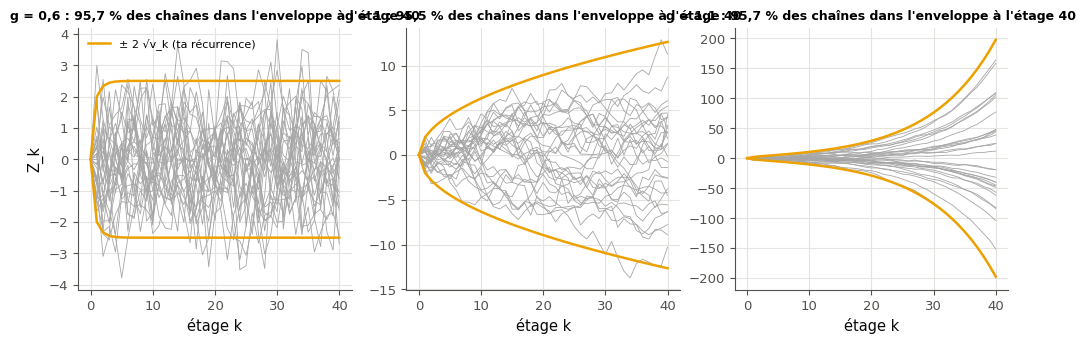

In [31]:
def simulate_chain(g, n_stages, n_chains, rng):
    """The (n_chains, n_stages + 1) array of the Z_k of n_chains independent chains: Z_0 = 0, then
    Z_{k+1} = g Z_k + N_k, with independent noises N_k of law N(0, 1) drawn with the generator rng."""
    Z = np.zeros((n_chains, n_stages + 1))
    for k in range(n_stages):
        Z[:, k + 1] = g * Z[:, k] + rng.normal(0.0, 1.0, size=n_chains)    # a new noise for every chain
    return Z


def variance_recurrence(g, s2, n_stages):
    """The NumPy array of the variances v_0 = 0, v_1, ..., v_{n_stages}, by v_{k+1} = g² v_k + s2."""
    v = np.zeros(n_stages + 1)
    for k in range(n_stages):
        v[k + 1] = g ** 2 * v[k] + s2
    return v


limit_16 = 1.0 / (1.0 - 0.6 ** 2)                  # the fixed point of v = g² v + 1
v_06_16 = variance_recurrence(0.6, 1.0, N_STAGES_16)
answer_M16_16a = round(limit_16, 4)
answer_M16_16b = float(variance_recurrence(1.0, 1.0, N_STAGES_16)[-1])
answer_M16_16c = round(float(variance_recurrence(1.1, 1.0, N_STAGES_16)[-1]), 1)
answer_M16_16d = next(k for k in range(N_STAGES_16 + 1) if abs(v_06_16[k] - limit_16) < 0.01 * limit_16)
chains_16 = simulate_chain(0.6, N_STAGES_16, N_CHAINS_16, np.random.default_rng(4932))
var_40_16 = float(np.var(chains_16[:, -1]))
answer_M16_16e = abs(var_40_16 - limit_16) < 0.05
print("a)", answer_M16_16a, " b)", answer_M16_16b, " c)", answer_M16_16c, " d)", answer_M16_16d, " e)", answer_M16_16e,
      f"(variance simulée de Z_40 : {var_40_16:.4f})")
print("écart relatif à la limite, g = 0,6 :", [f"{(limit_16 - v) / limit_16:.4f}" for v in v_06_16[:7]])
v_11_16 = variance_recurrence(1.1, 1.0, N_STAGES_16)
print("élargissement de l'enveloppe pour g = 1,1, √(v_k / v_k−1) aux étages 2, 5, 10 et 40 :",
      [round(float(math.sqrt(v_11_16[k] / v_11_16[k - 1])), 4) for k in (2, 5, 10, 40)])
print("part des chaînes dans ± 2 écarts-types (loi normale) :", round(math.erf(2 / math.sqrt(2)), 4))

fig, axes = plt.subplots(1, len(GAINS_16), figsize=(12.0, 3.4))
try:
    rng_fig_16 = np.random.default_rng(4933)
    stages_16 = np.arange(N_STAGES_16 + 1)
    for ax, g_16 in zip(axes, GAINS_16):
        theory_16 = np.asarray(variance_recurrence(g_16, 1.0, N_STAGES_16), dtype=float)
        chains_fig_16 = np.asarray(simulate_chain(g_16, N_STAGES_16, N_CHAINS_16, rng_fig_16), dtype=float)
        band_16 = 2 * np.sqrt(theory_16)                           # ± 2 standard deviations, from your recurrence
        inside_16 = float(np.mean(np.abs(chains_fig_16[:, -1]) <= band_16[-1]))
        ax.plot(stages_16, chains_fig_16[:30].T, color="0.65", lw=0.6)        # 30 of the simulated chains
        ax.plot(stages_16, band_16, color="C3", lw=1.8, label="± 2 √v_k (ta récurrence)")
        ax.plot(stages_16, -band_16, color="C3", lw=1.8)
        shown_16 = f"{g_16:g}".replace(".", ",")
        ax.set_title(f"g = {shown_16} : {fr(100 * inside_16, 1)} % des chaînes dans l'enveloppe à l'étage "
                     f"{N_STAGES_16}", fontsize=9)
        ax.set_xlabel("étage k")
    axes[0].set_ylabel("Z_k")
    axes[0].legend(fontsize=8, loc="upper left")
except BaseException:
    plt.close(fig)
    raise
plt.show()

In [32]:
from fractions import Fraction as Fr


def recurrence_16r(g, n):
    """v_n by v_{k+1} = g² v_k + 1, v_0 = 0, in exact fractions."""
    v = Fr(0)
    for _ in range(n):
        v = g ** 2 * v + 1
    return v


g6_16r, g11_16r = Fr(6, 10), Fr(11, 10)
limit_16r = 1 / (1 - g6_16r ** 2)
wbm.record("M16.16a", float(limit_16r), decimals=4,
           mistakes={"à chaque étage, la variance est multipliée par g², le carré du gain": float(1 / (1 - g6_16r)),
                     "le point fixe résout v = g² v + 1 : isole v": float(1 - g6_16r ** 2)})
wbm.record("M16.16b", float(recurrence_16r(Fr(1), 40)), decimals=6,
           mistakes={"compte les bruits ajoutés : v_0 = 0, avant le premier étage, et un bruit par étage":
                         {float(recurrence_16r(Fr(1), 41)), float(recurrence_16r(Fr(1), 39))},
                     "pour g = 1, la variance ne se stabilise pas : chaque étage ajoute la variance d'un bruit": 1.0})
wbm.record("M16.16c", float(recurrence_16r(g11_16r, 40)), decimals=1,
           mistakes={"à chaque étage, la variance est multipliée par g², le carré du gain":
                         float(sum(g11_16r ** k for k in range(40))),
                     "v_0 = 0 : la variance vient des bruits, un par étage, chacun amplifié par les étages suivants":
                         float(g11_16r ** 80),
                     "v_40 : quarante étages après v_0 = 0, un bruit par étage":
                         {float(recurrence_16r(g11_16r, 41)), float(recurrence_16r(g11_16r, 39))}})


def first_stage_16r(ratio):
    """The first k where the relative gap ratio^k to the limit is below 1 %."""
    return next(k for k in range(200) if ratio ** k < Fr(1, 100))


right_16r = first_stage_16r(g6_16r ** 2)
wbm.record("M16.16d", right_16r,
           fractional="le premier étage, un entier : vérifie l'inégalité pour ta valeur et pour la précédente",
           mistakes={"à cet étage, v_k est encore à plus de 1 % de sa limite : vérifie l'inégalité pour ta valeur":
                         right_16r - 1,
                     "c'est le PREMIER étage où v_k est à moins de 1 % de sa limite qui est demandé": right_16r + 1,
                     "l'écart à la limite est multiplié par g² à chaque étage, pas par g": first_stage_16r(g6_16r)})
wbm.record("M16.16e", True,
           mistakes={"ta variance simulée s'écarte de la limite : chaque chaîne part de Z_0 = 0 et reçoit un nouveau "
                     "bruit N(0, 1) à chaque étage ; np.var porte sur la colonne de l'étage 40": False})

WBM_ANSWER {"alt_coarse": ["9d37259a83a8cebdcd1db16d151be36c6e0f8912ec94e45eb6290869f5fa21a6"], "coarse_any": {"0": ["7e740d2f5fac6b736296f802a9f320de9a97865950c9cedf5cff1056ed8cdf1b"]}, "coarser": {"1": ["3f15277113ebb3d456b30badb7fcd5e6af5c97acb84ce56fbb56cf7b3b2e0e71"], "2": ["8ad0aa88db5f5a5cebd3928c10ad09e449904df89d6d79353b5685b5d6875f5d"]}, "decimals": 4, "hash": "12ac20e58f42c109b502e19fbe0c591d1eb33905b0a6245c00f2851c8fad49fa", "hash_coarse": "d65a20f5c869690799e805526fbfce3e3c01dfaf8511a5eee854a2edd9773bf4", "id": "M16.16a", "kind": "float", "magnitude": 0, "mistakes": {"5f75d6b92e489f162cb4197c2d0ec016439421195c87d73e58ccf6ba2fc6584d": "à chaque étage, la variance est multipliée par g², le carré du gain", "bdc3dd48b91ec160f7f0c122752bb375b34131ffc77de6b3a102997bbdee0a29": "le point fixe résout v = g² v + 1 : isole v"}, "sign": 1}
📝 Ex M16.16a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"0": ["586db22598c48de2313d78597e41197fae0d3c4bc7c34b04f70ec6c9

💡 a) Le point fixe de $v = 0{,}36\,v + 1$ est $\frac{1}{0{,}64} = 1{,}5625$, et $v_k = 1{,}5625\,(1 - 0{,}36^k)$ : l'écart relatif à la limite est $0{,}36^k$, multiplié par $g^2$ à chaque étage. d) $0{,}36^4 \approx 0{,}0168 > 0{,}01$ et $0{,}36^5 \approx 0{,}0060 < 0{,}01$ : l'étage 5. b) Pour $g = 1$, chaque étage ajoute 1 : $v_{40} = 40$, une variance qui croît comme $k$ (l'écart-type comme $\sqrt{k}$). c) Pour $g = 1{,}1$, $v_{40} = \frac{1{,}21^{40} - 1}{0{,}21} \approx 9\,749{,}5$ : au bout de quelques étages, $v_{k+1} \approx 1{,}21\,v_k$, et l'enveloppe $\pm 2\sqrt{v_k}$ s'élargit d'un facteur $\approx 1{,}1$ par étage. $Z_k$ est une somme de bruits normaux indépendants, donc normale : environ 95 % des chaînes ($P(\lvert Z \rvert \le 2\sigma) \approx 0{,}954$) restent dans l'enveloppe. e) La variance empirique de $Z_{40}$ s'écarte de la limite de quelques centièmes au plus : l'écart-type relatif d'une variance empirique sur 25 000 tirages est $\sqrt{2/25\,000} \approx 0{,}9\,\%$, soit $\approx 0{,}014$. La variance reste bornée si et seulement si $\lvert g \rvert < 1$ ; pour $\lvert g \rvert \ge 1$, elle grandit sans limite, linéairement pour $\lvert g \rvert = 1$, géométriquement au-delà.

### Ex M16.17 — L'image d'une figure par une suite d'applications affines du plan, en coordonnées homogènes 🎨 ★ ⏱️ 15 min
**Objectif :** écrire les matrices homogènes de transformations du plan et tracer les images successives d'une figure par leurs produits.  
**Prérequis :** fiche §2 ; Ex M16.12 · **Parcours :** C, E

La cellule fournie donne une flèche, `ARROW_17`, par ses 7 sommets rangés en lignes, et trois transformations du plan : $f_1$, la symétrie $(x, y) \mapsto (y, x)$ ; $f_2$, la translation de vecteur $(2, 0)$ ; $f_3$, l'homothétie de centre l'origine et de rapport 0,5. Écris :
- `transformations_17()`, qui rend la liste $[\mathbf{H}_1, \mathbf{H}_2, \mathbf{H}_3]$ de leurs matrices homogènes $3 \times 3$, pour des points en **lignes** (à la main, ou avec ta `homogeneous_matrix`, `mymath.affine.homogeneous_matrix`) ;
- `draw_images(ax, shape, matrices)`, qui dessine dans l'axe `ax` (sans en ouvrir d'autre) le polygone `shape` (un sommet par ligne), puis ses images successives par $\mathbf{H}_1$, $\mathbf{H}_1\mathbf{H}_2$, $\mathbf{H}_1\mathbf{H}_2\mathbf{H}_3$, … : passe les sommets en coordonnées homogènes $[\mathbf{x}, 1]$, multiplie-les par le produit des matrices, et garde les deux premières coordonnées. Une couleur par étape, une légende, des axes de même échelle (`ax.set_aspect("equal")`).

La cellule de vérification essaie tes trois matrices sur des points, appelle `draw_images(ax, ARROW_17, transformations_17())`, vérifie que la flèche et ses trois images sont tracées (leurs 7 sommets) dans l'axe reçu, avec une légende, puis affiche ta figure.

Dans ta copie : écris $\mathbf{H}_1\mathbf{H}_2\mathbf{H}_3$ et la formule de $(f_3 \circ f_2 \circ f_1)(x, y)$. Où va la pointe de la flèche, $(5, 2)$, à chaque étape ? Si l'on faisait l'homothétie **avant** la translation ($f_2 \circ f_3 \circ f_1$), quelle serait la dernière image, et pourquoi diffère-t-elle ? Pourquoi la dernière image a-t-elle une aire quatre fois plus petite que la flèche ?

In [33]:
ARROW_17 = np.array([[0.0, 1.0], [3.0, 1.0], [3.0, 0.0], [5.0, 2.0],
                     [3.0, 4.0], [3.0, 3.0], [0.0, 3.0]])     # an arrow: its 7 vertices, one per row
MAPS_17 = (lambda p: p[:, ::-1],                              # f1: the symmetry (x, y) ↦ (y, x)
           lambda p: p + np.array([2.0, 0.0]),                # f2: the translation of vector (2, 0)
           lambda p: 0.5 * p)                                 # f3: the homothety of centre the origin and ratio 0.5


def drawn_shapes_17(ax):
    """The sets of points drawn in ax: the (x, y) data of its lines, the vertices of its patches, the points of its
    collections."""
    shapes = [np.column_stack([line.get_xdata(), line.get_ydata()]).astype(float) for line in ax.lines]
    shapes += [np.asarray(patch.get_xy(), dtype=float).reshape(-1, 2) for patch in ax.patches
               if hasattr(patch, "get_xy")]
    for collection in ax.collections:
        shapes += [np.asarray(path.vertices, dtype=float) for path in collection.get_paths() if len(path.vertices) > 2]
        if len(collection.get_offsets()) > 2:
            shapes.append(np.asarray(collection.get_offsets(), dtype=float))
    return shapes


def same_vertices_17(points, want):
    """True when the points drawn are exactly the vertices of want, in any order (the first one repeated or not)."""
    got = np.unique(np.round(np.asarray(points, dtype=float).reshape(-1, 2), 6), axis=0)
    want = np.unique(np.round(np.asarray(want, dtype=float), 6), axis=0)
    return got.shape == want.shape and bool(np.allclose(got, want))

H1 H2 H3 = [[0.0, 0.5, 0.0], [0.5, 0.0, 0.0], [1.0, 0.0, 1.0]]
la pointe (5, 2) : [[2.0, 5.0], [4.0, 5.0], [2.0, 2.5]]
homothétie avant la translation, H1 H3 H2 = [[0.0, 0.5, 0.0], [0.5, 0.0, 0.0], [2.0, 0.0, 1.0]]
✅ H1, la symétrie (x, y) ↦ (y, x) envoie [x, y, 1] sur [f(x, y), 1]
✅ H2, la translation de vecteur (2, 0) envoie [x, y, 1] sur [f(x, y), 1]
✅ H3, l'homothétie de rapport 0,5 envoie [x, y, 1] sur [f(x, y), 1]
✅ draw_images dessine dans l'axe reçu
✅ la flèche de départ est tracée
✅ son image par f1 est tracée
✅ son image par f2 ∘ f1 est tracée
✅ son image par f3 ∘ f2 ∘ f1 est tracée
✅ une légende, une entrée par étape


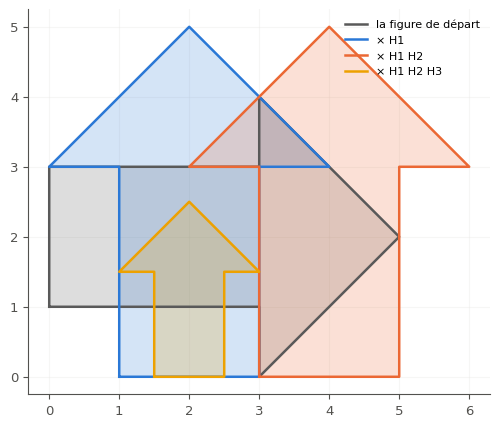

✅ Ex M16.17 : les trois matrices sont justes, et la flèche et ses trois images sont tracées dans l'axe reçu, avec une légende.


In [34]:
def transformations_17():
    """The homogeneous matrices [H1, H2, H3] (3 × 3, for points in rows) of f1, f2 and f3."""
    homogeneous_matrix = mymath.affine.homogeneous_matrix
    return [homogeneous_matrix([[0.0, 1.0], [1.0, 0.0]], [0.0, 0.0]),     # row 1 = image of (1, 0) = (0, 1)
            homogeneous_matrix(np.eye(2), [2.0, 0.0]),
            homogeneous_matrix(0.5 * np.eye(2), [0.0, 0.0])]


def draw_images(ax, shape, matrices):
    """In ax (and no other axes): the polygon shape (one vertex per row), then its images by H1, H1 H2, H1 H2 H3, ...
    computed in homogeneous coordinates; one colour per step, a legend."""
    rows = np.hstack([np.asarray(shape, dtype=float), np.ones((len(shape), 1))])   # [x, 1] for every vertex
    product = np.eye(rows.shape[1])
    steps = [("la figure de départ", rows)]
    for k, H in enumerate(matrices, start=1):
        product = product @ np.asarray(H, dtype=float)       # H1 H2 … Hk: the first map applied on the left
        steps.append(("× " + " ".join(f"H{j}" for j in range(1, k + 1)), rows @ product))
    for (label, points), color in zip(steps, ("0.35", "C0", "C1", "C3", "C4", "C5")):
        closed = np.vstack([points[:, :2], points[:1, :2]])                   # back to the first vertex
        ax.fill(closed[:, 0], closed[:, 1], color=color, alpha=0.2)
        ax.plot(closed[:, 0], closed[:, 1], "-", color=color, lw=1.8, label=label)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)


H1_17, H2_17, H3_17 = transformations_17()
print("H1 H2 H3 =", (H1_17 @ H2_17 @ H3_17).tolist())
tip_17 = np.array([5.0, 2.0, 1.0])                         # the tip of the arrow, [x, 1]
print("la pointe (5, 2) :", [(tip_17 @ H1_17)[:2].tolist(), (tip_17 @ H1_17 @ H2_17)[:2].tolist(),
                             (tip_17 @ H1_17 @ H2_17 @ H3_17)[:2].tolist()])
print("homothétie avant la translation, H1 H3 H2 =", (H1_17 @ H3_17 @ H2_17).tolist())


with checked("M16.17"):
    results_17 = []

    def report_17(ok, success, failure):
        results_17.append(bool(ok))
        print(("✅ " + success) if ok else ("❌ " + failure))

    matrices_17 = [np.asarray(H, dtype=float) for H in transformations_17()]
    if len(matrices_17) != 3:
        print(f"❌ Ex M16.17 : transformations_17 doit rendre la liste [H1, H2, H3] ; reçu {len(matrices_17)} matrice(s)")
        raise StopCheck
    probe_17 = np.array([[1.0, 2.0], [-3.0, 0.5], [0.0, -1.0]])                 # three points, in rows
    names_17 = ("H1, la symétrie (x, y) ↦ (y, x)", "H2, la translation de vecteur (2, 0)",
                "H3, l'homothétie de rapport 0,5")
    for matrix_17, map_17, name_17 in zip(matrices_17, MAPS_17, names_17):
        sends_17 = matrix_17.shape == (3, 3) and np.allclose(np.hstack([probe_17, np.ones((3, 1))]) @ matrix_17,
                                                             np.hstack([map_17(probe_17), np.ones((3, 1))]))
        report_17(sends_17, f"{name_17} envoie [x, y, 1] sur [f(x, y), 1]",
                  f"{name_17} n'envoie pas [x, y, 1] sur [f(x, y), 1] : avec des lignes, la partie linéaire en haut "
                  f"à gauche, la translation sur la dernière ligne, et la dernière colonne (0, 0, 1)")
    fig, ax = plt.subplots(figsize=(6.0, 5.0))
    try:
        opened_17 = drawn(draw_images, ax, ARROW_17, matrices_17)
    except BaseException:
        plt.close(fig)
        raise
    report_17(not opened_17, "draw_images dessine dans l'axe reçu",
              "draw_images doit dessiner dans l'axe reçu, sans ouvrir de figure (ni plt.figure ni plt.subplots)")
    shapes_17 = drawn_shapes_17(ax)
    steps_17 = [ARROW_17]
    for map_17 in MAPS_17:                              # f1, then f2 ∘ f1, then f3 ∘ f2 ∘ f1
        steps_17.append(map_17(steps_17[-1]))
    labels_17 = ("la flèche de départ", "son image par f1", "son image par f2 ∘ f1", "son image par f3 ∘ f2 ∘ f1")
    for want_17, label_17 in zip(steps_17, labels_17):
        report_17(any(same_vertices_17(s, want_17) for s in shapes_17), f"{label_17} est tracée",
                  f"je ne trouve pas {label_17} parmi tes tracés : ses 7 sommets sont les lignes de [x, 1] multipliées "
                  f"par le produit des matrices, sans la dernière coordonnée")
    entries_17 = len(ax.get_legend().get_texts()) if ax.get_legend() is not None else 0
    report_17(entries_17 >= 4, "une légende, une entrée par étape",
              f"ajoute une légende (ax.legend()), une entrée par étape (label=... dans chaque tracé) : j'en compte "
              f"{entries_17}")
    plt.show()
    verdict("M16.17", all(results_17), "les trois matrices sont justes, et la flèche et ses trois images sont tracées "
                                       "dans l'axe reçu, avec une légende.", "relis les lignes ❌ ci-dessus.")

💡 $\mathbf{H}_1 = \begin{pmatrix} 0 & 1 & 0 \\ 1 & 0 & 0 \\ 0 & 0 & 1 \end{pmatrix}$, $\mathbf{H}_2 = \begin{pmatrix} 1 & 0 & 0 \\ 0 & 1 & 0 \\ 2 & 0 & 1 \end{pmatrix}$, $\mathbf{H}_3 = \begin{pmatrix} 0{,}5 & 0 & 0 \\ 0 & 0{,}5 & 0 \\ 0 & 0 & 1 \end{pmatrix}$, et $\mathbf{H}_1\mathbf{H}_2\mathbf{H}_3 = \begin{pmatrix} 0 & 0{,}5 & 0 \\ 0{,}5 & 0 & 0 \\ 1 & 0 & 1 \end{pmatrix}$ : $(f_3 \circ f_2 \circ f_1)(x, y) = (0{,}5y + 1,\ 0{,}5x)$. La pointe $(5, 2)$ va en $(2, 5)$, puis $(4, 5)$, puis $(2, 2{,}5)$. Avec l'homothétie avant la translation, $\mathbf{H}_1\mathbf{H}_3\mathbf{H}_2$ a pour dernière ligne $(2, 0, 1)$ : la translation n'est plus réduite de moitié, et la dernière image est décalée de 1 vers la droite. L'homothétie de rapport 0,5 divise les longueurs par 2, donc les aires par 4 ; la symétrie et la translation conservent les aires.

## Partie C · Erreurs classiques, savoir-faire et défi

Fiche §1, §2, §4 et §5. Trois fonctions fausses à mesurer puis à corriger, un test de propriété de la matrice homogène, puis la loi du produit de deux uniformes.

### Ex M16.18 — Chasse à l'erreur : une matrice homogène écrite pour des colonnes et appliquée à des lignes, Var(XY) = Var X · Var Y, et (I − A)⁻¹ sur un graphe qui a un cycle 🐛 ★ ⏱️ 15 min
**Objectif :** reconnaître trois erreurs classiques qui ne lèvent aucune erreur Python (une matrice homogène dans la mauvaise convention, la variance d'un produit, une somme sur les chemins d'un graphe à cycle), mesurer leurs effets, puis les corriger.  
**Prérequis :** fiche §1, §2, §4 et §5 · **Parcours :** C, E

Une collègue a écrit trois fonctions (cellule fournie) ; leurs docstrings disent ce qu'elles doivent faire, et chacune a l'erreur que nomme le titre :
- `apply_affine(X, W, b)` doit rendre les images $\mathbf{x}\mathbf{W} + \mathbf{b}$ des points rangés en lignes dans `X`, en passant par la matrice homogène ;
- `product_variance(mean_x, var_x, mean_y, var_y)` doit rendre $\mathbb{V}(XY)$ pour $X$ et $Y$ indépendantes ;
- `paths_count(A, s, t)` doit rendre le nombre de chemins de $s$ à $t$ (deux nœuds distincts, numérotés à partir de 0) d'un graphe sans cycle, et lever une `ValueError` si le graphe a un cycle.

Aucune ne lève d'erreur sur les données de la cellule. Calcule à la main, puis vérifie en appelant les fonctions de la collègue :
- a) l'image du point `P_18` $= (1, 2)$ que rend `apply_affine(P_18, W_18, B_18)` (une liste de 2 nombres) ;
- b) la dernière coordonnée de $[1, 2, 1]\,\mathbf{H}$, avec la matrice $\mathbf{H}$ que construit `apply_affine` pour `W_18` et `B_18` (un nombre) ;
- c) ce que rend `paths_count(CYCLE_18, 0, 3)` (un nombre).

Corrige ensuite les trois fonctions : écris `apply_affine_fixed`, `product_variance_fixed` et `paths_count_fixed`, avec les mêmes arguments et les mêmes docstrings. La vérification les essaie sur des cas que tu ne vois pas : des applications de $\mathbb{R}^2$ dans $\mathbb{R}^2$, de $\mathbb{R}^3$ dans $\mathbb{R}^2$ et de $\mathbb{R}^2$ dans $\mathbb{R}^3$ ; des moyennes nulles ou non ; un graphe sans cycle à 6 nœuds, et deux graphes avec un cycle, dont un où $\mathbf{I} - \mathbf{A}$ n'est pas inversible.

In [35]:
def apply_affine(X, W, b):
    """The images x W + b of the points of X (one point per row), computed through the homogeneous matrix of the map
    x ↦ x W + b."""
    X, W, b = np.asarray(X, dtype=float), np.asarray(W, dtype=float), np.asarray(b, dtype=float)
    n, m = W.shape
    H = np.zeros((n + 1, m + 1))
    H[:n, :m] = W                                     # the linear part, at the top left
    H[:n, m] = b                                      # the translation, in the last column
    H[n, m] = 1.0
    rows = np.hstack([X, np.ones((len(X), 1))])       # [x, 1] for every point
    return (rows @ H)[:, :-1]


def product_variance(mean_x, var_x, mean_y, var_y):
    """The variance of the product X Y of two independent variables X and Y."""
    return var_x * var_y


def paths_count(A, s, t):
    """The number of paths (of at least one edge) from s to t, two distinct nodes of a graph without cycle of
    adjacency matrix A; a ValueError if the graph has a cycle."""
    A = np.asarray(A, dtype=float)
    return float(np.linalg.inv(np.eye(len(A)) - A)[s, t])


W_18 = np.array([[2.0, 1.0],
                 [0.0, 3.0]])                     # a map of the plane, x ↦ x W_18 + B_18
B_18 = np.array([-1.0, 4.0])
P_18 = np.array([[1.0, 2.0]])                     # one point, in a row
CYCLE_18 = np.array([[0, 0, 1, 1],
                     [1, 0, 0, 0],
                     [0, 0, 0, 1],
                     [0, 1, 0, 0]])               # 0 → 2, 0 → 3, 1 → 0, 2 → 3 and 3 → 1: a graph with a cycle

In [36]:
rows_18 = np.hstack([P_18, np.ones((1, 1))])                                 # [1, 2, 1]
H_col_18 = np.block([[W_18, B_18[:, None]], [np.zeros((1, 2)), np.ones((1, 1))]])     # the colleague's matrix
answer_M16_18a = apply_affine(P_18, W_18, B_18)[0].tolist()
answer_M16_18b = float((rows_18 @ H_col_18)[0, -1])
answer_M16_18c = paths_count(CYCLE_18, 0, 3)
print("a)", answer_M16_18a, " (la bonne image :", (P_18 @ W_18 + B_18)[0].tolist(), ")  b)", answer_M16_18b,
      " c)", answer_M16_18c)
print("chemins de 0 à 3 de 1 à 8 arêtes :", [int(np.linalg.matrix_power(CYCLE_18, k)[0, 3]) for k in range(1, 9)])

a) [2.0, 7.0]  (la bonne image : [1.0, 11.0] )  b) 8.0  c) -2.0
chemins de 0 à 3 de 1 à 8 arêtes : [1, 1, 0, 1, 2, 1, 1, 3]


In [37]:
import sympy

w_18r, b_18r, p_18r = np.array([[2.0, 1.0], [0.0, 3.0]]), np.array([-1.0, 4.0]), np.array([1.0, 2.0])
h_col_18r = np.block([[w_18r, b_18r[:, None]], [np.zeros((1, 2)), np.ones((1, 1))]])   # the colleague's matrix
row_18r = np.append(p_18r, 1.0) @ h_col_18r
wbm.record("M16.18a", row_18r[:2].tolist(),
           mistakes={"a) demande ce que RENVOIE la fonction de la collègue : refais son produit [x, 1] H, avec sa "
                     "matrice H": (p_18r @ w_18r + b_18r).tolist(),
                     "la fonction multiplie la LIGNE [x, 1] par H, H à droite : pas H par une colonne":
                         (h_col_18r @ np.append(p_18r, 1.0))[:2].tolist(),
                     "la fonction rend chaque image sans sa dernière coordonnée : deux nombres": row_18r.tolist()})
wbm.record("M16.18b", float(row_18r[2]), decimals=6,
           mistakes={"la dernière colonne de cette H n'est pas (0, …, 0, 1) : refais le produit de [x, 1] par sa "
                     "dernière colonne": 1.0})
cycle_18r = sympy.Matrix([[0, 0, 1, 1], [1, 0, 0, 0], [0, 0, 0, 1], [0, 1, 0, 0]])
simple_18r = 2                                     # the paths without a repeated node: 0 → 3 and 0 → 2 → 3
wbm.record("M16.18c", float((sympy.eye(4) - cycle_18r).inv()[0, 3]), decimals=6,
           mistakes={"c) demande ce que RENVOIE la fonction de la collègue, le coefficient de (I − A)⁻¹, pas un nombre "
                     "de chemins": float(simple_18r)})

WBM_ANSWER {"decimals": 0, "element_hashes": ["433af4ecef4c4fac6dfc9f25e33ce6ac7bb84be23a400f8447ccec9d5fb5cac8", "42561e4879383a2941231537eb1e50feb9f7a43640f2b882a9193df1e3916480"], "hash": "1948c06ffa47ee770efc17254e0ae9185ff3f369d2b5363147b43ed12f52e4ad", "id": "M16.18a", "integer": true, "kind": "array", "mistakes": {"06b8e4ddce666a2154bdce053d1a3744a1d8001fd8b7daa13bdab59236ff281e": "la fonction multiplie la LIGNE [x, 1] par H, H à droite : pas H par une colonne", "70d692c104097c84a092e2feff588f02f132ef69897e1980c846de2789d1fe42": "la fonction rend chaque image sans sa dernière coordonnée : deux nombres", "a99f8bc5fc0b9d8708016a918fbd14dedf867b4bc1167afaaea5fada74bcf13e": "a) demande ce que RENVOIE la fonction de la collègue : refais son produit [x, 1] H, avec sa matrice H"}, "shape": [2]}
📝 Ex M16.18a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"coarse_any": {"0": ["87f91f7638a8c8ac375974670c9d5dc30aaf60037577f05ba8f48b436747c8a8"]}, "coarser": {"1": ["a1313a435e4a7073

**Corrige maintenant les trois fonctions.** La cellule qui suit la tienne les vérifie sur des cas que tu ne vois pas.

In [38]:
def apply_affine_fixed(X, W, b):
    """The images x W + b of the points of X (one point per row), computed through the homogeneous matrix of the map
    x ↦ x W + b."""
    X, W, b = np.asarray(X, dtype=float), np.asarray(W, dtype=float), np.asarray(b, dtype=float)
    n, m = W.shape
    H = np.zeros((n + 1, m + 1))
    H[:n, :m] = W                                     # the linear part, at the top left, as it is
    H[n, :m] = b                                      # the translation, on the last ROW
    H[n, m] = 1.0                                     # the last column is (0, …, 0, 1)
    rows = np.hstack([X, np.ones((len(X), 1))])
    return (rows @ H)[:, :-1]


def product_variance_fixed(mean_x, var_x, mean_y, var_y):
    """The variance of the product X Y of two independent variables X and Y."""
    return var_x * var_y + var_x * mean_y ** 2 + var_y * mean_x ** 2


def paths_count_fixed(A, s, t):
    """The number of paths (of at least one edge) from s to t, two distinct nodes of a graph without cycle of
    adjacency matrix A; a ValueError if the graph has a cycle."""
    A = np.asarray(A, dtype=float)
    n = len(A)
    if np.linalg.matrix_power((A != 0).astype(int), n).any():     # a path of n edges repeats a node: a cycle
        raise ValueError("the graph has a cycle")
    return float(np.linalg.inv(np.eye(n) - A)[s, t])


with checked("M16.18"):
    results_18 = []

    def report_18(ok, success, failure):
        results_18.append(bool(ok))
        print(("✅ " + success) if ok else ("❌ " + failure))

    def outcome_18(call):
        """(the value of call(), "") or (None, the error it raises); NotImplementedError goes through: ⏳."""
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", RuntimeWarning)
                return call(), ""
        except NotImplementedError:
            raise
        except Exception as exc:  # noqa: BLE001 - reported below
            return None, f"{type(exc).__name__} : {str(exc)[:120]}"

    rng_18 = np.random.default_rng(4936)                   # (A) maps of R² into R², of R³ into R², of R² into R³
    for n_18, m_18 in ((2, 2), (3, 2), (2, 3)):
        w_c18 = rng_18.integers(-4, 5, size=(n_18, m_18)).astype(float)
        b_c18 = rng_18.integers(-4, 5, size=m_18).astype(float)
        x_c18 = rng_18.integers(-3, 4, size=(4, n_18)).astype(float)
        got_18, error_18 = outcome_18(lambda: apply_affine_fixed(x_c18.copy(), w_c18.copy(), b_c18.copy()))
        good_18 = (not error_18 and got_18 is not None and np.shape(got_18) == (4, m_18)
                   and np.allclose(np.asarray(got_18, dtype=float), x_c18 @ w_c18 + b_c18))
        shown_18 = (f"ta fonction lève {error_18}" if error_18 else "reçu None" if got_18 is None
                    else f"reçu {np.round(np.asarray(got_18, dtype=float), 3).tolist()}")
        report_18(good_18, f"apply_affine_fixed : 4 points, une application de R^{n_18} dans R^{m_18}",
                  f"apply_affine_fixed, 4 points et une application de R^{n_18} dans R^{m_18} (W de forme "
                  f"({n_18}, {m_18})) : attendu les images x W + b, une ligne par point, de forme (4, {m_18}) ; "
                  f"{shown_18}")
    for args_18 in ((2.5, 0.2, -3.0, 0.4), (0.0, 2.0, 0.0, 3.0), (4.0, 0.0, -2.5, 1.2)):   # (B)
        got_18, error_18 = outcome_18(lambda: product_variance_fixed(*args_18))
        want_18 = args_18[1] * args_18[3] + args_18[1] * args_18[2] ** 2 + args_18[3] * args_18[0] ** 2
        good_18 = (not error_18 and isinstance(got_18, (int, float, np.integer, np.floating))
                   and math.isclose(float(got_18), want_18, rel_tol=1e-9))
        report_18(good_18, f"product_variance_fixed{args_18}",
                  f"product_variance_fixed{args_18} : attendu la variance de X Y pour X et Y indépendantes ; "
                  + (f"ta fonction lève {error_18}" if error_18 else f"reçu {got_18!r}"))
    rng_dag_18 = np.random.default_rng(4937)                # (C) a graph without cycle, then two graphs with a cycle
    dag_18 = np.triu((rng_dag_18.random((6, 6)) < 0.6).astype(float), 1)
    order_18 = rng_dag_18.permutation(6)
    dag_18 = dag_18[np.ix_(order_18, order_18)]
    paths_18 = sum(np.linalg.matrix_power(dag_18, k) for k in range(1, 6))    # A + A² + … + A⁵
    wrong_pairs_18 = []
    for s_18, t_18 in ((s, t) for s in range(6) for t in range(6) if s != t):
        got_18, error_18 = outcome_18(lambda: paths_count_fixed(dag_18.copy(), s_18, t_18))
        if error_18 or got_18 is None or not math.isclose(float(got_18), float(paths_18[s_18, t_18]), abs_tol=1e-9):
            wrong_pairs_18.append(f"de {s_18} à {t_18} : attendu {paths_18[s_18, t_18]:g}, "
                                  + (error_18 or f"reçu {got_18!r}"))
    report_18(not wrong_pairs_18, "paths_count_fixed : les 30 couples de nœuds d'un graphe sans cycle à 6 nœuds",
              "paths_count_fixed, sur un graphe sans cycle à 6 nœuds : " + " ; ".join(wrong_pairs_18[:2]))
    cycles_18 = {"un graphe à 5 nœuds avec un cycle, où I − A est inversible":
                     np.array([[0, 0, 1, 0, 0], [0, 0, 0, 1, 1], [1, 1, 0, 0, 1], [0, 0, 1, 0, 0], [0, 0, 0, 0, 0]]),
                 "un graphe à 4 nœuds avec le cycle 0 → 1 → 2 → 0, où I − A n'est pas inversible":
                     np.array([[0, 1, 0, 0], [0, 0, 1, 0], [1, 0, 0, 1], [0, 0, 0, 0]])}
    for label_18, cycle_18 in cycles_18.items():
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", RuntimeWarning)
                got_18 = paths_count_fixed(cycle_18.copy(), 0, len(cycle_18) - 1)
            report_18(False, "", f"paths_count_fixed, {label_18} : attendu ValueError, reçu {got_18!r}")
        except NotImplementedError:
            raise
        except Exception as exc:  # noqa: BLE001 - only a ValueError of the function itself is right
            report_18(type(exc) is ValueError, f"paths_count_fixed, {label_18} : ValueError levée ({exc})",
                      f"paths_count_fixed, {label_18} : attendu une ValueError levée par ta fonction, reçu "
                      f"{type(exc).__name__} ({str(exc)[:80]}) : vérifie l'absence de cycle AVANT de calculer")
    verdict("M16.18", all(results_18), "les trois fonctions corrigées passent tous les cas.",
            "relis les lignes ❌ ci-dessus.")

✅ apply_affine_fixed : 4 points, une application de R^2 dans R^2
✅ apply_affine_fixed : 4 points, une application de R^3 dans R^2
✅ apply_affine_fixed : 4 points, une application de R^2 dans R^3
✅ product_variance_fixed(2.5, 0.2, -3.0, 0.4)
✅ product_variance_fixed(0.0, 2.0, 0.0, 3.0)
✅ product_variance_fixed(4.0, 0.0, -2.5, 1.2)
✅ paths_count_fixed : les 30 couples de nœuds d'un graphe sans cycle à 6 nœuds
✅ paths_count_fixed, un graphe à 5 nœuds avec un cycle, où I − A est inversible : ValueError levée (the graph has a cycle)
✅ paths_count_fixed, un graphe à 4 nœuds avec le cycle 0 → 1 → 2 → 0, où I − A n'est pas inversible : ValueError levée (the graph has a cycle)
✅ Ex M16.18 : les trois fonctions corrigées passent tous les cas.


**Après la vérification**, dans ta copie : pour chaque fonction de la collègue, que calcule-t-elle exactement, et quelle formule de la fiche aurait-il fallu suivre ? Pour quels vecteurs $\mathbf{b}$ `apply_affine` donnerait-elle la bonne image ? Pour quelles moyennes `product_variance` a-t-elle raison ? Combien de chemins vont de 0 à 3 dans `CYCLE_18`, et que penser du nombre trouvé en c) ?

💡 a) La collègue range $\mathbf{W}$ en haut à gauche, mais $\mathbf{b}$ dans la dernière **colonne**, comme pour des points en colonnes : $\mathbf{H} = \begin{pmatrix} 2 & 1 & -1 \\ 0 & 3 & 4 \\ 0 & 0 & 1 \end{pmatrix}$ et $[1, 2, 1]\,\mathbf{H} = (2,\ 1 + 6,\ -1 + 8 + 1) = (2, 7, 8)$. Elle rend $(2, 7) = \mathbf{x}\mathbf{W}$ au lieu de $(2 - 1, 7 + 4) = (1, 11)$ : la translation a disparu, et b) la dernière coordonnée vaut $\mathbf{x} \cdot \mathbf{b} + 1 = 8$ au lieu de 1 (le 1 de $[\mathbf{x}, 1]$ ne rencontre jamais $\mathbf{b}$). Elle n'est juste que si $\mathbf{b} = \mathbf{0}$, quand il n'y a pas de translation. `product_variance` n'a raison que si $\mathbb{V}(X)\,\mathbb{E}[Y]^2 = 0$ et $\mathbb{V}(Y)\,\mathbb{E}[X]^2 = 0$, par exemple si les deux moyennes sont nulles. c) $\mathbf{I} - \mathbf{A}$ est inversible pour `CYCLE_18`, et le coefficient $(0, 3)$ de son inverse vaut $-2$ : un « nombre de chemins » négatif. Les chemins de 0 à 3 sont en nombre infini (on peut tourner sur $0 \to 3 \to 1 \to 0$ ou $0 \to 2 \to 3 \to 1 \to 0$), et $\mathbf{I} + \mathbf{A} + \mathbf{A}^2 + \cdots$ diverge : l'égalité avec $(\mathbf{I} - \mathbf{A})^{-1}$ n'a lieu que sans cycle. Quand $\mathbf{I} - \mathbf{A}$ n'est pas inversible, la fonction lève `LinAlgError` (une sous-classe de `ValueError`, mais avec le mauvais message) : il faut tester le cycle avant.

### Ex M16.19 — Un test de propriété : la matrice homogène d'une composée est le produit des matrices homogènes 🛠️ ★ ⏱️ 15 min
**Objectif :** écrire un test de propriété sur des tirages aléatoires (formes et valeurs), qui vérifie une composition sur des images de points, et s'assurer qu'il attrape des implémentations fausses.  
**Prérequis :** fiche §2 ; Ex M16.12 · **Parcours :** C

Écris `test_composition_is_a_product(homogeneous_matrix)`, une fonction de test dans le style de pytest (des `assert` avec un message qui dit le cas), qui reçoit une implémentation `homogeneous_matrix(W, b)` et vérifie la propriété du §2 : faire $f_1$ puis $f_2$, c'est multiplier $[\mathbf{x}, 1]$ par $\mathbf{H}_1\mathbf{H}_2$. Avec un générateur de graine 4935 (`np.random.default_rng(4935)`, créé dans le test), tire **au moins 20 paires** d'applications affines, $f_1 : \mathbf{x} \mapsto \mathbf{x}\mathbf{W}_1 + \mathbf{b}_1$ de $\mathbb{R}^n$ dans $\mathbb{R}^m$ et $f_2 : \mathbf{y} \mapsto \mathbf{y}\mathbf{W}_2 + \mathbf{b}_2$ de $\mathbb{R}^m$ dans $\mathbb{R}^k$, avec $n$, $m$ et $k$ tirés entre 1 et 4 et des coefficients de loi normale, puis, pour chaque paire, quelques points $\mathbf{x}$ :
- vérifie d'abord la forme de chaque matrice : $(n + 1, m + 1)$ pour $\mathbf{H}_1$, $(m + 1, k + 1)$ pour $\mathbf{H}_2$ ;
- compare $[\mathbf{x}, 1]\,\mathbf{H}_1\mathbf{H}_2$ à $[f_2(f_1(\mathbf{x})), 1]$, où $f_2(f_1(\mathbf{x}))$ est calculé directement, point par point (`np.allclose`).

La propriété se vérifie sur des **images de points** : ne calcule ni la matrice ni le vecteur de translation de la composée.

La vérification appelle ton test sur la matrice homogène de la référence, où il doit **passer**, et compte les matrices qu'il construit ; puis sur deux implémentations fausses de la cellule fournie, où il doit **échouer** (par un `assert`, pas par une autre erreur) : `homogeneous_last_column`, la translation dans la dernière colonne, comme pour des points en colonnes ; `homogeneous_corner_zero`, un 0 au lieu du 1 en bas à droite. Toutes deux ont la bonne forme.

Dans ta copie : quel `assert` attrape chacune des deux fausses matrices, et sur quel tirage ? Un test qui ne regarderait qu'**une** application à la fois, en comparant les $m$ premières coordonnées de $[\mathbf{x}, 1]\,\mathbf{H}$ à $f(\mathbf{x})$, attraperait-il `homogeneous_corner_zero` ? Et un test qui ne vérifierait que les formes ? Pourquoi tirer des $\mathbf{W}$ de toutes les formes, et des coefficients au hasard plutôt que des petits entiers choisis (que se passerait-il avec $\mathbf{b} = \mathbf{0}$) ?

In [39]:
ref_19 = wbm.load_mymath("ref", alias="mymath_ref").affine


def homogeneous_last_column(W, b):
    """A wrong matrix: [[W, c], [0, 1]], the translation in the last column, as for column vectors (the column c
    holds b, cut or completed with zeros to the n rows of W)."""
    W, b = np.asarray(W, dtype=float), np.asarray(b, dtype=float)
    n, m = W.shape
    H = np.zeros((n + 1, m + 1))
    H[:n, :m], H[n, m] = W, 1.0
    H[:min(n, m), m] = b[:min(n, m)]
    return H


def homogeneous_corner_zero(W, b):
    """A wrong matrix: [[W, 0], [b, 0]], a 0 instead of the 1 at the bottom right."""
    W, b = np.asarray(W, dtype=float), np.asarray(b, dtype=float)
    n, m = W.shape
    H = np.zeros((n + 1, m + 1))
    H[:n, :m], H[n, :m] = W, b
    return H


WRONG_19 = {"homogeneous_last_column (la translation dans la dernière colonne)": homogeneous_last_column,
            "homogeneous_corner_zero (un 0 en bas à droite)": homogeneous_corner_zero}

In [40]:
def test_composition_is_a_product(homogeneous_matrix):
    """[x, 1] H1 H2 = [f2(f1(x)), 1] for random affine maps f1 of R^n into R^m and f2 of R^m into R^k (seed 4935),
    checked on images of points, the shapes of H1 and H2 first."""
    rng = np.random.default_rng(4935)
    for draw in range(25):
        n, m, k = (int(d) for d in rng.integers(1, 5, size=3))
        W1, b1 = rng.normal(size=(n, m)), rng.normal(size=m)
        W2, b2 = rng.normal(size=(m, k)), rng.normal(size=k)
        H1, H2 = np.asarray(homogeneous_matrix(W1, b1)), np.asarray(homogeneous_matrix(W2, b2))
        assert H1.shape == (n + 1, m + 1), f"draw {draw}: H1 has the shape {H1.shape}, not {(n + 1, m + 1)}"
        assert H2.shape == (m + 1, k + 1), f"draw {draw}: H2 has the shape {H2.shape}, not {(m + 1, k + 1)}"
        for x in rng.normal(size=(3, n)):
            got = np.append(x, 1.0) @ H1 @ H2
            want = np.append((x @ W1 + b1) @ W2 + b2, 1.0)           # f2(f1(x)), computed point by point
            assert np.allclose(got, want), (f"draw {draw}, x = {np.round(x, 3).tolist()}: [x, 1] H1 H2 = "
                                            f"{np.round(got, 3).tolist()}, not [f2(f1(x)), 1] = {np.round(want, 3).tolist()}")


for label_19s, wrong_19s in WRONG_19.items():               # which assert catches each wrong matrix, and where
    try:
        test_composition_is_a_product(wrong_19s)
        print(label_19s, ": not caught")
    except AssertionError as exc:
        print(label_19s, ":", exc)


with checked("M16.19"):
    if len(inspect.signature(test_composition_is_a_product).parameters) != 1:
        raise TypeError("ton test prend un seul argument, l'implémentation à tester : "
                        "def test_composition_is_a_product(homogeneous_matrix)")
    results_19, shapes_19 = [], []

    def report_19(ok, success, failure):
        results_19.append(bool(ok))
        print(("✅ " + success) if ok else ("❌ " + failure))

    def recorded_19(W, b):
        """The reference homogeneous_matrix, which records the shape of each W."""
        shapes_19.append(tuple(np.shape(W)))
        return ref_19.homogeneous_matrix(W, b)

    try:
        test_composition_is_a_product(recorded_19)       # your test on the right matrix: ⏳ while it is not written
        why_19 = ""
    except AssertionError as exc:
        why_19 = str(exc)[:200] or "un assert sans message"
    report_19(not why_19, "ton test passe sur la bonne matrice homogène",
              f"ton test échoue sur la bonne matrice homogène (celle de la référence) : il refuse une implémentation "
              f"juste ({why_19})")
    report_19(len(shapes_19) >= 40, f"ton test construit {len(shapes_19)} matrices",
              f"ton test ne construit que {len(shapes_19)} matrice(s) : il en faut au moins 40, 20 paires "
              f"d'applications")
    report_19(any(len(s) == 2 and s[0] != s[1] for s in shapes_19), "des applications de R^n dans R^m avec n ≠ m",
              "tire aussi des applications de R^n dans R^m avec n ≠ m : les formes font partie de la propriété")
    hints_19 = {"homogeneous_last_column": "tire des translations b1 et b2 non nulles, et compare les images des "
                                           "points, pas seulement les formes",
                "homogeneous_corner_zero": "compare TOUTES les coordonnées de [x, 1] H1 H2, la dernière comprise, à "
                                           "[f2(f1(x)), 1]"}
    for label_19, wrong_19 in WRONG_19.items():
        try:
            test_composition_is_a_product(wrong_19)
            report_19(False, "", f"ton test passe sur {label_19} : il ne la voit pas ; {hints_19[wrong_19.__name__]}")
        except AssertionError:
            report_19(True, f"ton test échoue sur {label_19}", "")
        except NotImplementedError:
            raise
        except Exception as exc:  # noqa: BLE001 - a crash is not a failed assert
            report_19(False, "", f"ton test plante sur {label_19} ({type(exc).__name__} : {str(exc)[:100]}) au lieu "
                                 f"d'échouer sur un assert : vérifie d'abord la forme de chaque matrice")
    verdict("M16.19", all(results_19), "ton test accepte la bonne matrice, tire des formes variées et attrape les deux "
                                       "fausses.", "relis les lignes ❌ ci-dessus.")

homogeneous_last_column (la translation dans la dernière colonne) : draw 0, x = [-1.651]: [x, 1] H1 H2 = [2.056, -1.818], not [f2(f1(x)), 1] = [2.675, 1.0]
homogeneous_corner_zero (un 0 en bas à droite) : draw 0, x = [-1.651]: [x, 1] H1 H2 = [1.304, 0.0], not [f2(f1(x)), 1] = [2.675, 1.0]
✅ ton test passe sur la bonne matrice homogène
✅ ton test construit 50 matrices
✅ des applications de R^n dans R^m avec n ≠ m
✅ ton test échoue sur homogeneous_last_column (la translation dans la dernière colonne)
✅ ton test échoue sur homogeneous_corner_zero (un 0 en bas à droite)
✅ Ex M16.19 : ton test accepte la bonne matrice, tire des formes variées et attrape les deux fausses.


💡 Les deux fausses matrices ont la bonne forme : un test des formes seul ne voit rien, ce sont les images qui les attrapent, dès le premier tirage. `homogeneous_last_column` envoie $[\mathbf{x}, 1]$ sur $[\mathbf{x}\mathbf{W}, \mathbf{x} \cdot \mathbf{c} + 1]$ : la translation disparaît, et la dernière coordonnée ne vaut plus 1. `homogeneous_corner_zero` donne $[\mathbf{x}, 1]\,\mathbf{H}_1 = [\mathbf{x}\mathbf{W}_1 + \mathbf{b}_1, 0]$ : sur une seule application, les $m$ premières coordonnées sont justes ; c'est la composition qui la révèle, puisque le 0 final efface $\mathbf{b}_2$ à l'étape suivante (et la dernière coordonnée vaut 0). Des formes variées vérifient la propriété pour tous les $n$, $m$, $k$ ; des coefficients quelconques évitent les coïncidences qui rendent justes des matrices fausses : avec $\mathbf{b} = \mathbf{0}$, `homogeneous_last_column` passerait.

### Ex M16.20 — Défi : la loi du produit de deux uniformes indépendantes, sa densité et ses deux premiers moments 🏆 ★★★ ⏱️ 25 min
**Objectif :** trouver la loi du produit de deux variables uniformes indépendantes (fonction de répartition, densité, médiane) et ses deux premiers moments, et confronter la densité à un histogramme.  
**Prérequis :** fiche §5 ; M02b · **Parcours :** C

$U$ et $V$ sont indépendantes, de loi uniforme sur $[0 ; 1]$, et $Z = UV$. Trouve :
- a) $\mathbb{E}[Z]$ (une fraction irréductible entre guillemets) ;
- b) $\mathbb{V}(Z)$ (une fraction irréductible entre guillemets) ;
- c) $P\big(Z \le \frac{1}{4}\big)$ (4 décimales) ;
- d) la médiane de $Z$, le nombre $m$ tel que $P(Z \le m) = \frac{1}{2}$ (4 décimales) ;
- e) **l'objectif chiffré** : écris `density_20(z)`, la densité de $Z$ en un point $z$ de $]0 ; 1[$ (un `float`). La vérification tire $10^6$ valeurs de $Z$ (graine 4940), en trace l'histogramme (50 classes sur $[0 ; 1]$, normalisé comme une densité), et compare ta densité à sa hauteur au centre de chaque classe de $[0{,}05 ; 0{,}95]$ : l'écart moyen doit rester **sous 0,05**.

a) et b) se calculent sans la loi de $Z$ (fiche §5). Pour c) à e), trouve d'abord la fonction de répartition $F(z) = P(Z \le z)$ pour $0 < z < 1$ : c'est l'aire de la partie $\{(u, v) : uv \le z\}$ du carré $[0 ; 1]^2$ (fais un dessin : une hyperbole coupe le carré) ; la densité est sa dérivée. Pour d), une équation à résoudre numériquement (une dichotomie, ou `scipy.optimize.brentq`).

La cellule de vérification compare tes valeurs, puis calcule l'écart de e), trace l'histogramme et ta densité, et enregistre si l'objectif est atteint.

Dans ta copie : écris $F$, puis la densité, et vérifie que son intégrale sur $]0 ; 1]$ vaut 1. Retrouve a) et b) par des intégrales avec ta densité. Pourquoi la densité tend-elle vers $+\infty$ en 0, alors que son aire reste finie ? Pourquoi la médiane est-elle si loin de l'espérance ?

In [41]:
N_DRAWS_20 = 10 ** 6         # the draws of the check of e)

In [42]:
from scipy.optimize import brentq


def cdf_20(z):
    """F(z) = P(U V ≤ z) for 0 < z ≤ 1: the strip u ≤ z (every v), plus the area under v = z/u for u from z to 1."""
    return z - z * math.log(z)


def density_20(z):
    """The density of Z = U V at a point z of ]0, 1[ (a float)."""
    return -math.log(z)                                  # F'(z) = 1 − ln z − 1


answer_M16_20a, answer_M16_20b = "1/4", "7/144"          # E[U]E[V] ; E[U²]E[V²] − E[Z]² = 1/9 − 1/16
answer_M16_20c = round(cdf_20(0.25), 4)
answer_M16_20d = round(brentq(lambda m: cdf_20(m) - 0.5, 1e-9, 1.0), 4)
print("a)", answer_M16_20a, " b)", answer_M16_20b, " c)", answer_M16_20c, " d)", answer_M16_20d)
rng_check_20 = np.random.default_rng(4941)
z_check_20 = rng_check_20.random(N_DRAWS_20) * rng_check_20.random(N_DRAWS_20)
print("contrôle par simulation (graine 4941) : moyenne", round(float(z_check_20.mean()), 4), " ; variance",
      round(float(z_check_20.var()), 5), "(7/144 ≈", round(7 / 144, 5), ") ; P(Z ≤ 1/4) ≈",
      round(float(np.mean(z_check_20 <= 0.25)), 4), " ; médiane ≈", round(float(np.median(z_check_20)), 4))

a) 1/4  b) 7/144  c) 0.5966  d) 0.1867


contrôle par simulation (graine 4941) : moyenne 0.25  ; variance 0.0486 (7/144 ≈ 0.04861 ) ; P(Z ≤ 1/4) ≈ 0.5969  ; médiane ≈ 0.1866


In [43]:
wbm.record("M16.20a", "1/4", kind="fraction", simplified=True,
           mistakes={"E[UV] = E[U] E[V] pour des variables indépendantes": "1/2"})
wbm.record("M16.20b", "7/144", kind="fraction", simplified=True,
           mistakes={"V(UV) n'est pas V(U) V(V) : les moyennes non nulles comptent": "1/144",
                     "V(Z) = E[Z²] − E[Z]² : retranche le carré de l'espérance": "1/9"})
f_20r = lambda z: z - z * math.log(z)                   # noqa: E731 - P(UV ≤ z), from the area under v = z/u
wbm.record("M16.20c", f_20r(0.25), decimals=4,
           mistakes={"Z = UV n'est pas uniforme : calcule l'aire de la région {uv ≤ 1/4} du carré unité": 0.25,
                     "P(Z ≤ 1/4) est l'aire du côté des PETITS produits, sous l'hyperbole uv = 1/4": 1 - f_20r(0.25),
                     "pour u ≤ 1/4, tout v convient : cette bande de la région compte aussi": f_20r(0.25) - 0.25})
lo_20r, hi_20r = 1e-9, 1.0
for _ in range(200):                                   # the median by bisection: F(m) = 1/2
    mid_20r = (lo_20r + hi_20r) / 2
    lo_20r, hi_20r = (mid_20r, hi_20r) if f_20r(mid_20r) < 0.5 else (lo_20r, mid_20r)
wbm.record("M16.20d", (lo_20r + hi_20r) / 2, decimals=4,
           mistakes={"la médiane de Z n'est ni son espérance ni le produit des médianes de U et V : résous "
                     "P(Z ≤ m) = 1/2": 0.25,
                     "Z n'est pas uniforme : résous P(Z ≤ m) = 1/2 avec sa fonction de répartition": 0.5})
wbm.record("M16.20e", True,
           mistakes={"ta densité s'écarte de l'histogramme : la densité est la DÉRIVÉE de la fonction de répartition "
                     "F(z) = P(Z ≤ z), l'aire de la région {uv ≤ z} du carré unité": False})

WBM_ANSWER {"hash": "86cdbc0db5f0f46835c3be50ab48997479a61a822e6167e236926342f9558b1b", "id": "M16.20a", "kind": "fraction", "mistakes": {"0d8f4956099a2acf127d449efd937d158c8cd761682e62a2ef671dabcb287c1e": "E[UV] = E[U] E[V] pour des variables indépendantes"}, "sign": 1, "simplified": true}
📝 Ex M16.20a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "2fc4a082f53f06c07daeaf7c1414f5703cdae0b828f331422530bcd76f37e947", "id": "M16.20b", "kind": "fraction", "mistakes": {"ae9325f38b8d171782099e6b7a633f41564e0411c0a8ebf177dfa934cc20833f": "V(Z) = E[Z²] − E[Z]² : retranche le carré de l'espérance", "da24aab531baf81e7dba6d25459777bda5ecf0dd4730eeba200fe7357022b233": "V(UV) n'est pas V(U) V(V) : les moyennes non nulles comptent"}, "sign": 1, "simplified": true}
📝 Ex M16.20b : réponse enregistrée (fraction).
WBM_ANSWER {"coarse_any": {"0": ["273def0ea622790704622f666d57545df13ba73198b1c55b087be6f17cf02418"], "1": ["f5dc7a923804d653bfcb5ba2cd45ccd42e7995740fe5418abaeb7a7811221be2"]}, "coars

écart moyen entre ta densité et l'histogramme, sur les 46 classes de [0,05 ; 0,95] : 0,0050 (objectif : moins de 0,05)


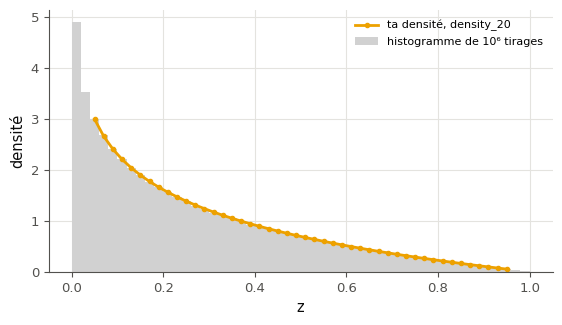

✅ Ex M16.20e : Bravo !


In [44]:
with checked("M16.20e"):
    rng_20 = np.random.default_rng(4940)
    draws_20 = rng_20.random(N_DRAWS_20) * rng_20.random(N_DRAWS_20)      # 10⁶ values of Z = U V
    heights_20, edges_20 = np.histogram(draws_20, bins=50, range=(0.0, 1.0), density=True)
    centers_20 = (edges_20[:-1] + edges_20[1:]) / 2
    kept_20 = (centers_20 > 0.05 - 1e-9) & (centers_20 < 0.95 + 1e-9)    # the classes of [0.05 ; 0.95]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        yours_20 = np.array([float(density_20(float(z))) for z in centers_20[kept_20]])
    gap_20 = float(np.mean(np.abs(yours_20 - heights_20[kept_20])))
    print(f"écart moyen entre ta densité et l'histogramme, sur les {int(kept_20.sum())} classes de [0,05 ; 0,95] : "
          f"{fr(gap_20, 4)} (objectif : moins de 0,05)")
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    ax.bar(centers_20, heights_20, width=edges_20[1] - edges_20[0], color="0.82", label="histogramme de 10⁶ tirages")
    ax.plot(centers_20[kept_20], yours_20, "o-", color="C3", ms=3, label="ta densité, density_20")
    ax.set_xlabel("z")
    ax.set_ylabel("densité")
    ax.legend(fontsize=8)
    plt.show()
    wbm.check("M16.20e", bool(gap_20 < 0.05), computed=True)

💡 La région $\{uv \le z\}$ du carré contient la bande $u \le z$ (tout $v$ convient : aire $z$), puis, pour $u \ge z$, la partie sous l'hyperbole $v = \frac{z}{u}$ : $\int_z^1 \frac{z}{u}\,du = -z\ln z$. Donc $F(z) = z - z\ln z$, et la densité est $F'(z) = -\ln z$, qui tend vers $+\infty$ en 0 mais d'aire $\int_0^1 -\ln z\,dz = 1$. a) $\mathbb{E}[Z] = \frac12 \times \frac12 = \frac14$ ; b) $\mathbb{E}[Z^2] = \frac13 \times \frac13 = \frac19$, d'où $\mathbb{V}(Z) = \frac19 - \frac{1}{16} = \frac{7}{144}$ (et non $\frac{1}{144} = \mathbb{V}(U)\,\mathbb{V}(V)$) ; avec la densité, $\int_0^1 -z\ln z\,dz = \frac14$ et $\int_0^1 -z^2\ln z\,dz = \frac19$. c) $F(\frac14) = \frac{1 + \ln 4}{4} \approx 0{,}5966$. d) $m - m\ln m = \frac12$ donne $m \approx 0{,}1867$, bien sous l'espérance $0{,}25$ : la loi est très asymétrique, avec beaucoup de petits produits et une longue traîne vers 1. e) L'écart moyen entre $-\ln z$ et l'histogramme est de l'ordre de $0{,}005$ : le bruit d'échantillonnage et la largeur des classes, là où la densité est très courbée (près de 0,05).

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu écrire une application affine dans les deux conventions, avec la forme de chaque objet, et compter ses paramètres ?
2. Sais-tu composer et inverser des applications affines par leurs matrices homogènes, dans le bon ordre ?
3. Sais-tu compter des chemins par les puissances de la matrice d'adjacence, reconnaître un graphe sans cycle et sommer sur ses chemins ?
4. Sais-tu calculer l'espérance et la variance d'un produit de variables indépendantes, et la variance d'une somme de produits par des multiplicateurs centrés ?
5. Sais-tu suivre une variance multipliée d'étage en étage, et dire quand elle se stabilise, croît ou explose ?

**La suite** : le chapitre 16 de workbookIA, qui se sert de ces outils, puis M17 (jacobienne et règle de la chaîne), juste avant le chapitre 17 de workbookIA.